Name: Manas Tiwari

GitHub Username: mt431

USC ID: 5446032746


# Tiwari_Manas_HW4


## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import warnings
import zipfile
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from IPython.display import display
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits


Get the AReM Data Set

In [2]:
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13",
           "var_rss13", "avg_rss23", "var_rss23"]
recordings = []

with zipfile.ZipFile("../data/AReM.zip") as archive:
    files = [name for name in archive.namelist() if name.endswith(".csv")]
    files.sort(key=lambda name: (name.split("/")[0],
                                int(name.split("dataset")[1].split(".")[0])))

    for filename in files:
        lines = archive.read(filename).decode("utf-8").splitlines()
        # Needed to handle empty trailing fields
        measurements = "\n".join(line.strip().rstrip(",") for line in lines[5:])
        data = pd.read_csv(StringIO(measurements), sep=r"[,\s]+",
                           engine="python", header=None, names=columns)
        assert data.shape[1] == 7
        assert not data.isna().any().any(), filename
        assert all(pd.api.types.is_numeric_dtype(data[col]) for col in columns)
        assert data["time"].is_unique, filename
        assert data["time"].is_monotonic_increasing, filename
        expected_rows = 479 if filename == "sitting/dataset8.csv" else 480
        assert len(data) == expected_rows, filename
        expected_times = pd.Index(range(0, 120000, 250))
        missing_times = expected_times.difference(data["time"])
        assert data["time"].isin(expected_times).all(), filename
        assert list(missing_times) == ([13500] if expected_rows == 479 else []), filename

        recordings.append({"activity": filename.split("/")[0],
                           "filename": filename.split("/")[-1], "data": data})

assert len(recordings) == 88
assert len({recording["activity"] for recording in recordings}) == 7
summary = {
    "recordings": len(recordings),
    "activities": len({recording["activity"] for recording in recordings}),
    "sensor_series_per_recording": len(columns) - 1,
    "recordings_with_480_rows": sum(len(recording["data"]) == 480 for recording in recordings),
    "recordings_with_479_rows": sum(len(recording["data"]) == 479 for recording in recordings),
    "missing_entries": sum(recording["data"].isna().sum().sum() for recording in recordings)
}
summary


{'recordings': 88,
 'activities': 7,
 'sensor_series_per_recording': 6,
 'recordings_with_480_rows': 87,
 'recordings_with_479_rows': 1,
 'missing_entries': np.int64(0)}

Data loading notes:

- Whitespace-separated measurements in dataset4.csv and trailing commas in dataset9.csv & dataset14.csv needed to be handled explicitly while loading
- dataset8.csv is missing the observation at timestamp 13500. All other recordings contain 480 rows
- 479 rows are preserved without linear interpolation

### (b) Test and Train Data

In [3]:
train_recordings = []
test_recordings = []

for recording in recordings:
    activity = recording["activity"]
    filename = recording["filename"]
    dataset_number = int(filename.removeprefix("dataset").removesuffix(".csv"))
    test_cutoff = 2 if activity in ["bending1", "bending2"] else 3

    if dataset_number <= test_cutoff:
        test_recordings.append(recording)
    else:
        train_recordings.append(recording)

assert len(train_recordings) == 69
assert len(test_recordings) == 19
assert len(train_recordings) + len(test_recordings) == len(recordings)

split_counts = {"training_recordings": len(train_recordings),
                "test_recordings": len(test_recordings)}
split_counts


{'training_recordings': 69, 'test_recordings': 19}

### (c) Feature Extraction

#### i. Research

Common time-domain features used in time series classification are:

- Minimum and maximum
- Mean and median:
- Standard deviation and variance
- First and third quartiles
- Root mean square (RMS) and energy
- Skewness and kurtosis
- Mean absolute change

#### ii. Extraction

In [4]:
feature_rows = []

for recording in recordings:
    row = {}
    for number, sensor in enumerate(columns[1:], start=1):
        series = recording["data"][sensor]
        row.update({
            f"min{number}": series.min(),
            f"max{number}": series.max(),
            f"mean{number}": series.mean(),
            f"median{number}": series.median(),
            f"std{number}": series.std(ddof=1),
            f"1st_quart{number}": series.quantile(0.25, interpolation="linear"),
            f"3rd_quart{number}": series.quantile(0.75, interpolation="linear")
        })
    feature_rows.append(row)

features = pd.DataFrame(feature_rows, index=range(1, len(recordings) + 1))
features.index.name = "Instance"

assert features.shape == (88, 42)
assert not features.isna().any().any()
features


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


#### iii. Standard Deviation

In [5]:
feature_std = features.std(ddof=1)
rng = np.random.default_rng(42)
bootstrap_std = []

for _ in range(1000):
    sample = features.sample(n=len(features), replace=True, random_state=rng)
    bootstrap_std.append(sample.std(ddof=1).to_numpy())

bootstrap_std = np.array(bootstrap_std)
bounds = np.percentile(bootstrap_std, [5, 95], axis=0)

std_intervals = pd.DataFrame({
    "Standard deviation": feature_std,
    "90% CI lower": bounds[0],
    "90% CI upper": bounds[1]
})
std_intervals.index.name = "Feature"

assert bootstrap_std.shape == (1000, 42)
assert np.isfinite(std_intervals.to_numpy()).all()
assert (std_intervals["90% CI lower"] <= std_intervals["90% CI upper"]).all()
std_intervals


,Standard deviation,90% CI lower,90% CI upper
Feature,,,
min1,9.569975,8.209638,10.787225
max1,4.394362,3.326747,5.322249
mean1,5.335718,4.722033,5.898977
median1,5.440054,4.785337,6.003385
std1,1.772153,1.568859,1.944177
1st_quart1,6.153590,5.597144,6.664643
3rd_quart1,5.138925,4.334445,5.842911
min2,0.000000,0.000000,0.000000
max2,5.062729,4.644618,5.397581


1,000 bootstrap resamples as per piazza post recommendation and each column's sample standard deviation is calculated. The 5th and 95th percentiles of these estimates form the 90% percentile bootstrap interval. The generator is initialized with seed 42 for reproducibility.


#### iv. Select Features

To support the selection, I compare activity separation and redundancy across all six sensor series. For each feature, the separation score (between activity variation/total variation) is used to compare as per Codex suggestion. A larger score means more of the observed variation is associated with differences in activity means. It is scale independent and is not classification accuracy. Constant features receive a score of zero. Each statistic type is summarized by averaging its six sensor scores.


In [6]:
activities = pd.Series([r["activity"] for r in recordings],
                       index=features.index, name="Activity")
feature_types = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
activity_groups = features.groupby(activities)
between_ss = (activity_groups.mean().sub(features.mean()).pow(2)
              .mul(activity_groups.size(), axis=0).sum())
total_ss = features.sub(features.mean()).pow(2).sum()
eta_squared = between_ss.div(total_ss.where(total_ss > 0)).fillna(0)
separation = pd.DataFrame({
    sensor: [eta_squared[f"{kind}{sensor}"] for kind in feature_types]
    for sensor in range(1, 7)
}, index=feature_types)

sensor_correlations = []
for sensor in range(1, 7):
    correlation = features[[f"{kind}{sensor}" for kind in feature_types]].corr().abs()
    correlation.index = feature_types
    correlation.columns = feature_types
    sensor_correlations.append(correlation)

correlation_sum = sum(c.fillna(0) for c in sensor_correlations)
correlation_count = sum(c.notna().astype(int) for c in sensor_correlations)
mean_abs_correlation = correlation_sum / correlation_count

separation_summary = separation.copy()
separation_summary.columns = [f"Sensor {sensor}" for sensor in range(1, 7)]
separation_summary["Mean separation"] = separation.mean(axis=1)
separation_summary.sort_values("Mean separation", ascending=False)


,Sensor 1,Sensor 2,Sensor 3,Sensor 4,Sensor 5,Sensor 6,Mean separation
mean,0.610361,0.985517,0.719671,0.984206,0.801709,0.983721,0.847531
median,0.612583,0.976638,0.667522,0.986836,0.771889,0.982162,0.832938
3rd_quart,0.494904,0.983791,0.755100,0.981154,0.790892,0.984550,0.831732
1st_quart,0.658795,0.962565,0.654034,0.958746,0.762721,0.970753,0.827936
std,0.428296,0.971608,0.543072,0.924884,0.392898,0.934949,0.699284
max,0.120726,0.838748,0.766729,0.725300,0.807124,0.776255,0.672481
min,0.549317,0.000000,0.645386,0.000000,0.750529,0.055939,0.333529


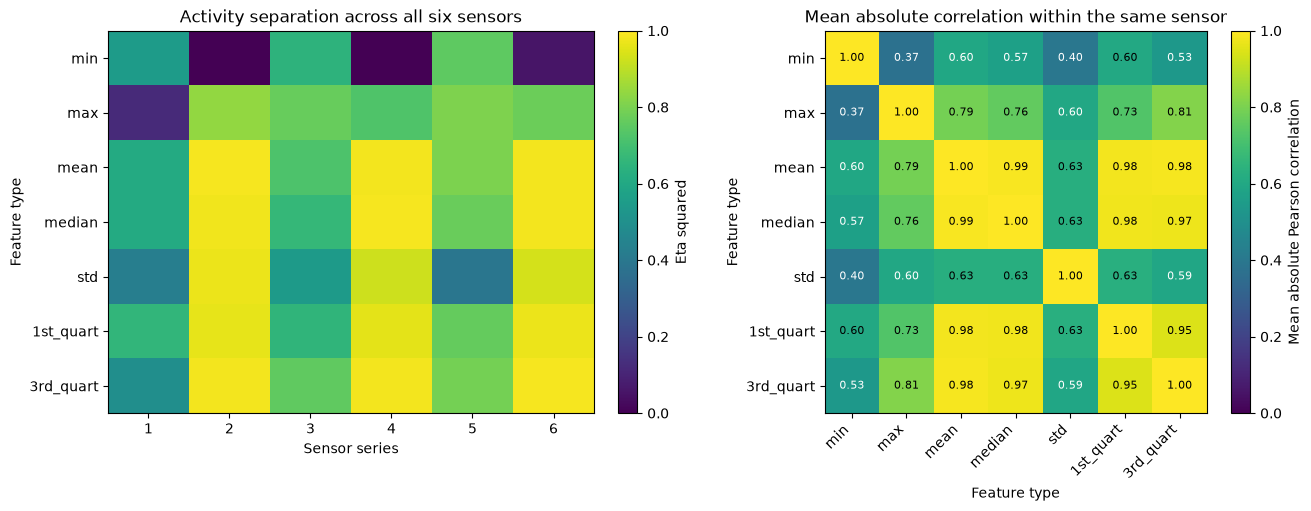

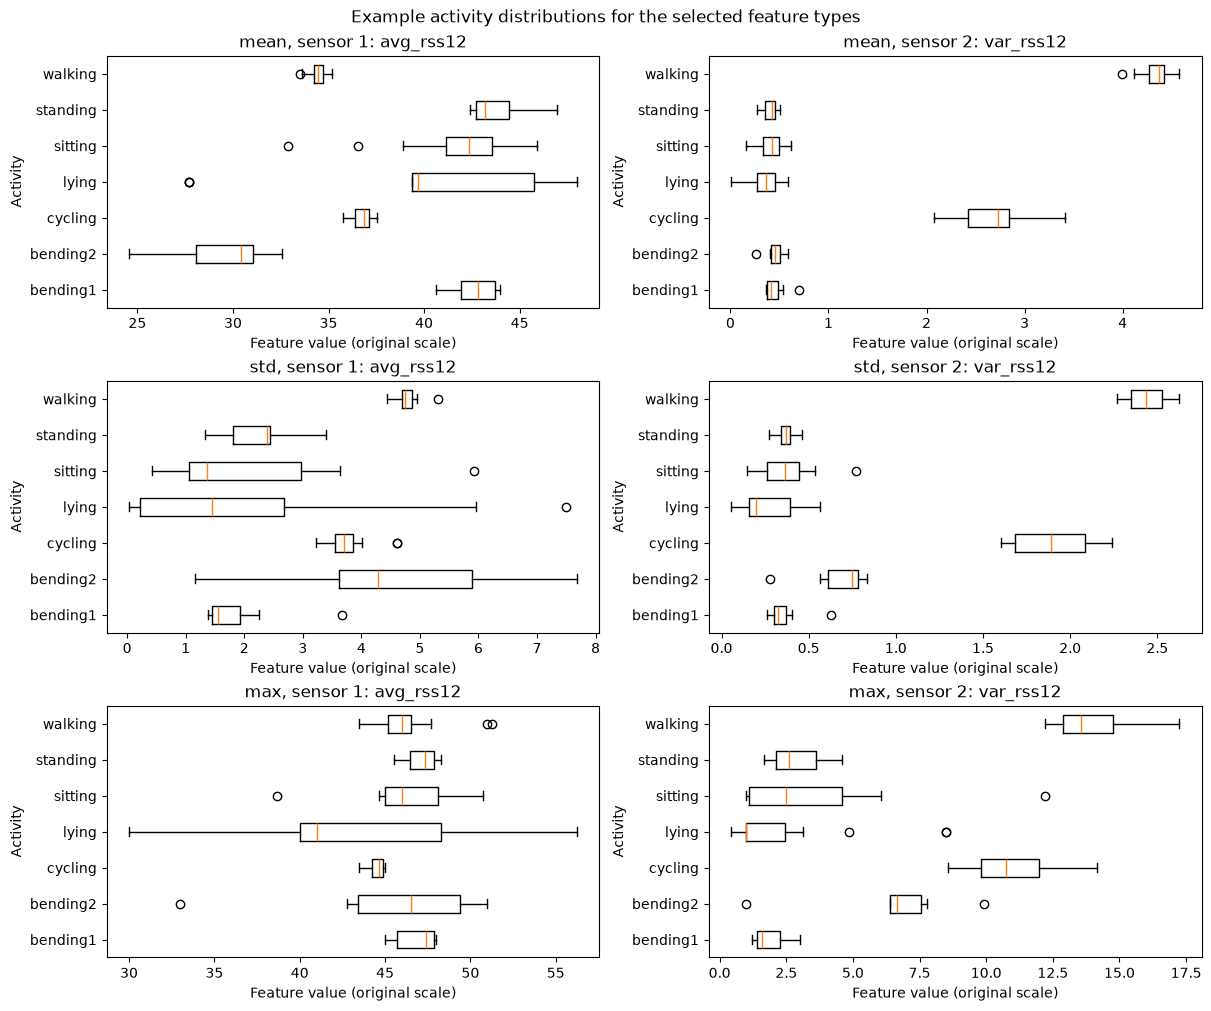

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
image = axes[0].imshow(separation, vmin=0, vmax=1, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(6), range(1, 7))
axes[0].set_yticks(range(7), feature_types)
axes[0].set_xlabel("Sensor series")
axes[0].set_ylabel("Feature type")
axes[0].set_title("Activity separation across all six sensors")
fig.colorbar(image, ax=axes[0], label="Eta squared")
image = axes[1].imshow(mean_abs_correlation, vmin=0, vmax=1, cmap="viridis")
axes[1].set_xticks(range(7), feature_types, rotation=45, ha="right")
axes[1].set_yticks(range(7), feature_types)
axes[1].set_xlabel("Feature type")
axes[1].set_ylabel("Feature type")
axes[1].set_title("Mean absolute correlation within the same sensor")
for row in range(7):
    for column in range(7):
        value = mean_abs_correlation.iloc[row, column]
        axes[1].text(column, row, f"{value:.2f}", ha="center", va="center",
                     color="black" if value > 0.6 else "white", fontsize=8)
fig.colorbar(image, ax=axes[1], label="Mean absolute Pearson correlation")
plt.show()

selected_types = ["mean", "std", "max"]
activity_order = sorted(activities.unique())
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for row, kind in enumerate(selected_types):
    for column, sensor in enumerate([1, 2]):
        ax = axes[row, column]
        values = [features.loc[activities == activity, f"{kind}{sensor}"]
                  for activity in activity_order]
        ax.boxplot(values, orientation="horizontal", tick_labels=activity_order)
        ax.set_title(f"{kind}, sensor {sensor}: {columns[sensor]}")
        ax.set_xlabel("Feature value (original scale)")
        ax.set_ylabel("Activity")
fig.suptitle("Example activity distributions for the selected feature types")
plt.show()


From the figures, the mean, standard deviation, and maximum seem to be the most useful as well as provide non redundant information.

- Mean has the highest average activity-separation score (0.848). Median and the quartiles also separate activities well, but their average absolute correlations with mean exceed 0.98, so I avoid selecting several of these similar summaries.
- Standard deviation has an average separation score of 0.699 and a lower average absolute correlation with mean (0.625), contributing information about fluctuations within a recording.
- Maximum has an average separation score of 0.672 and correlations of 0.791 with mean and 0.600 with standard deviation. It provides a peak summary with less redundancy than the median or quartiles. Minimum is less correlated with mean, but its average separation score is only 0.334; two of its sensor columns are constant.


- # Homework 4 code below-

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

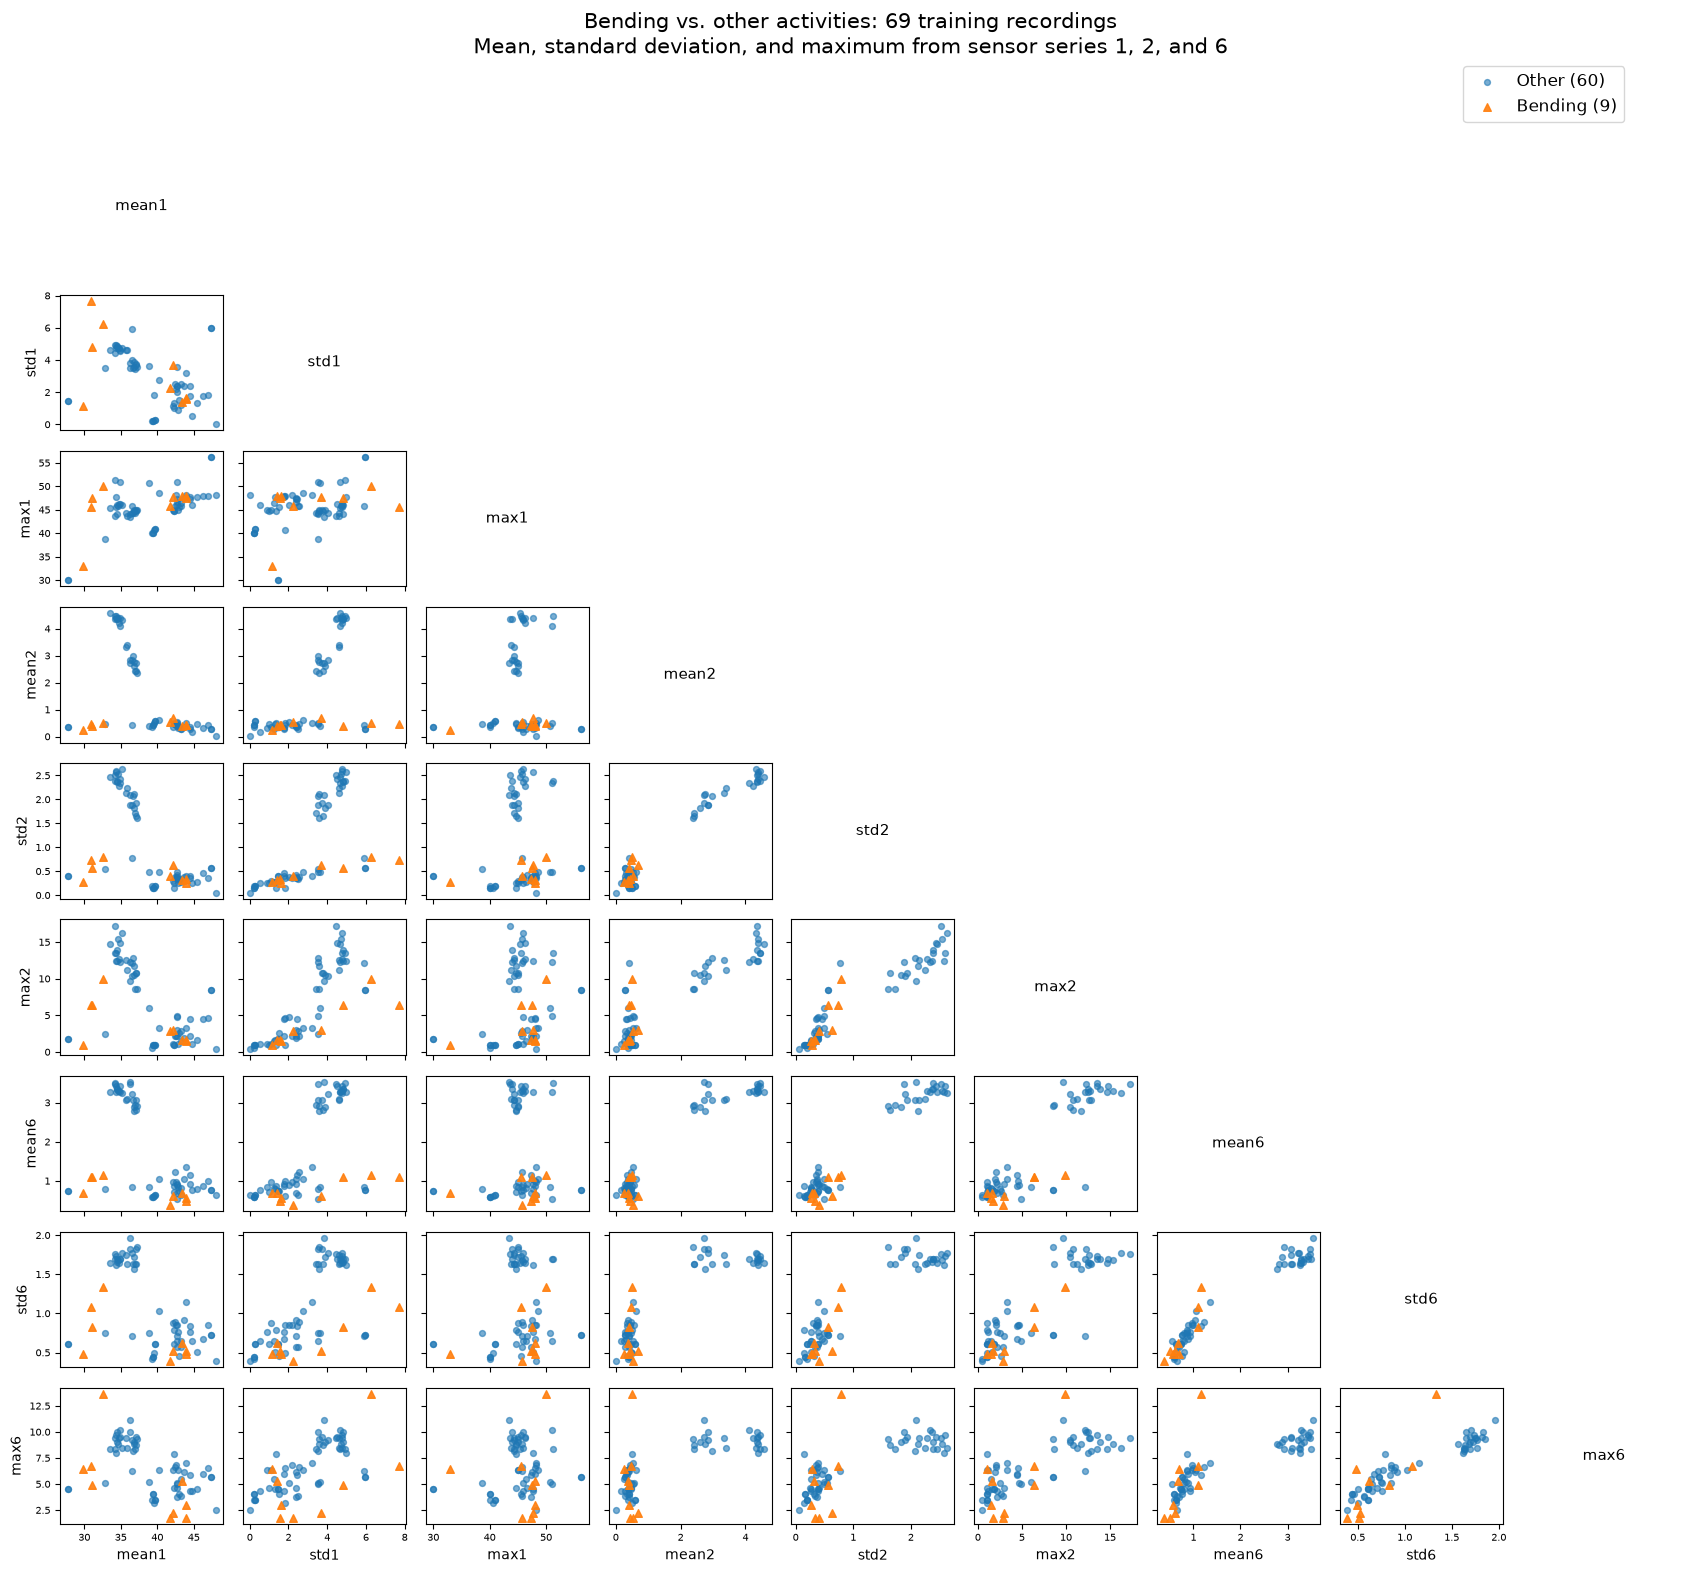

In [8]:

for split, subset in [("train", train_recordings), ("test", test_recordings)]:
    for recording in subset:
        recording["split"] = split
recording_info = pd.DataFrame([
    {"activity": r["activity"], "filename": r["filename"], "split": r["split"]}
    for r in recordings
], index=features.index)
train_features = features.loc[recording_info["split"] == "train"].copy()
test_features = features.loc[recording_info["split"] == "test"].copy()
split_summary = pd.crosstab(recording_info["activity"], recording_info["split"])[["train", "test"]]
split_summary.loc["Total"] = split_summary.sum()

plot_columns = [f"{kind}{sensor}" for sensor in [1, 2, 6] for kind in selected_types]
plot_features = train_features[plot_columns]
plot_activities = recording_info.loc[train_features.index, "activity"]
is_bending = plot_activities.isin(["bending1", "bending2"])


fig, axes = plt.subplots(9, 9, figsize=(17, 16))
for row, y_feature in enumerate(plot_columns):
    for column, x_feature in enumerate(plot_columns):
        ax = axes[row, column]
        if row <= column:
            ax.set_axis_off()
            if row == column:
                ax.text(0.5, 0.5, x_feature, ha="center", va="center",
                        transform=ax.transAxes, fontsize=11)
            continue

        ax.scatter(plot_features.loc[~is_bending, x_feature],
                   plot_features.loc[~is_bending, y_feature],
                   color="tab:blue", s=18, alpha=0.6,
                   label=f"Other ({(~is_bending).sum()})")
        ax.scatter(plot_features.loc[is_bending, x_feature],
                   plot_features.loc[is_bending, y_feature],
                   color="tab:orange", marker="^", s=30, alpha=0.9,
                   label=f"Bending ({is_bending.sum()})")
        ax.tick_params(labelsize=7, labelbottom=row == 8, labelleft=column == 0)
        if row == 8:
            ax.set_xlabel(x_feature, fontsize=10)
        if column == 0:
            ax.set_ylabel(y_feature, fontsize=10)

handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.96, 0.95), fontsize=12)
fig.suptitle("Bending vs. other activities: 69 training recordings\n"
             "Mean, standard deviation, and maximum from sensor series 1, 2, and 6", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Each point is one training recording. Orange triangles represent bending1 and bending2 while the blue circles represent the other activities. We can observe that the bending recordings often have low mean2 and mean6, but overlap with other activities in that region. The plots suggest some useful features without showing complete separation for any individual pair.


#### ii. Plots after splitting each recording


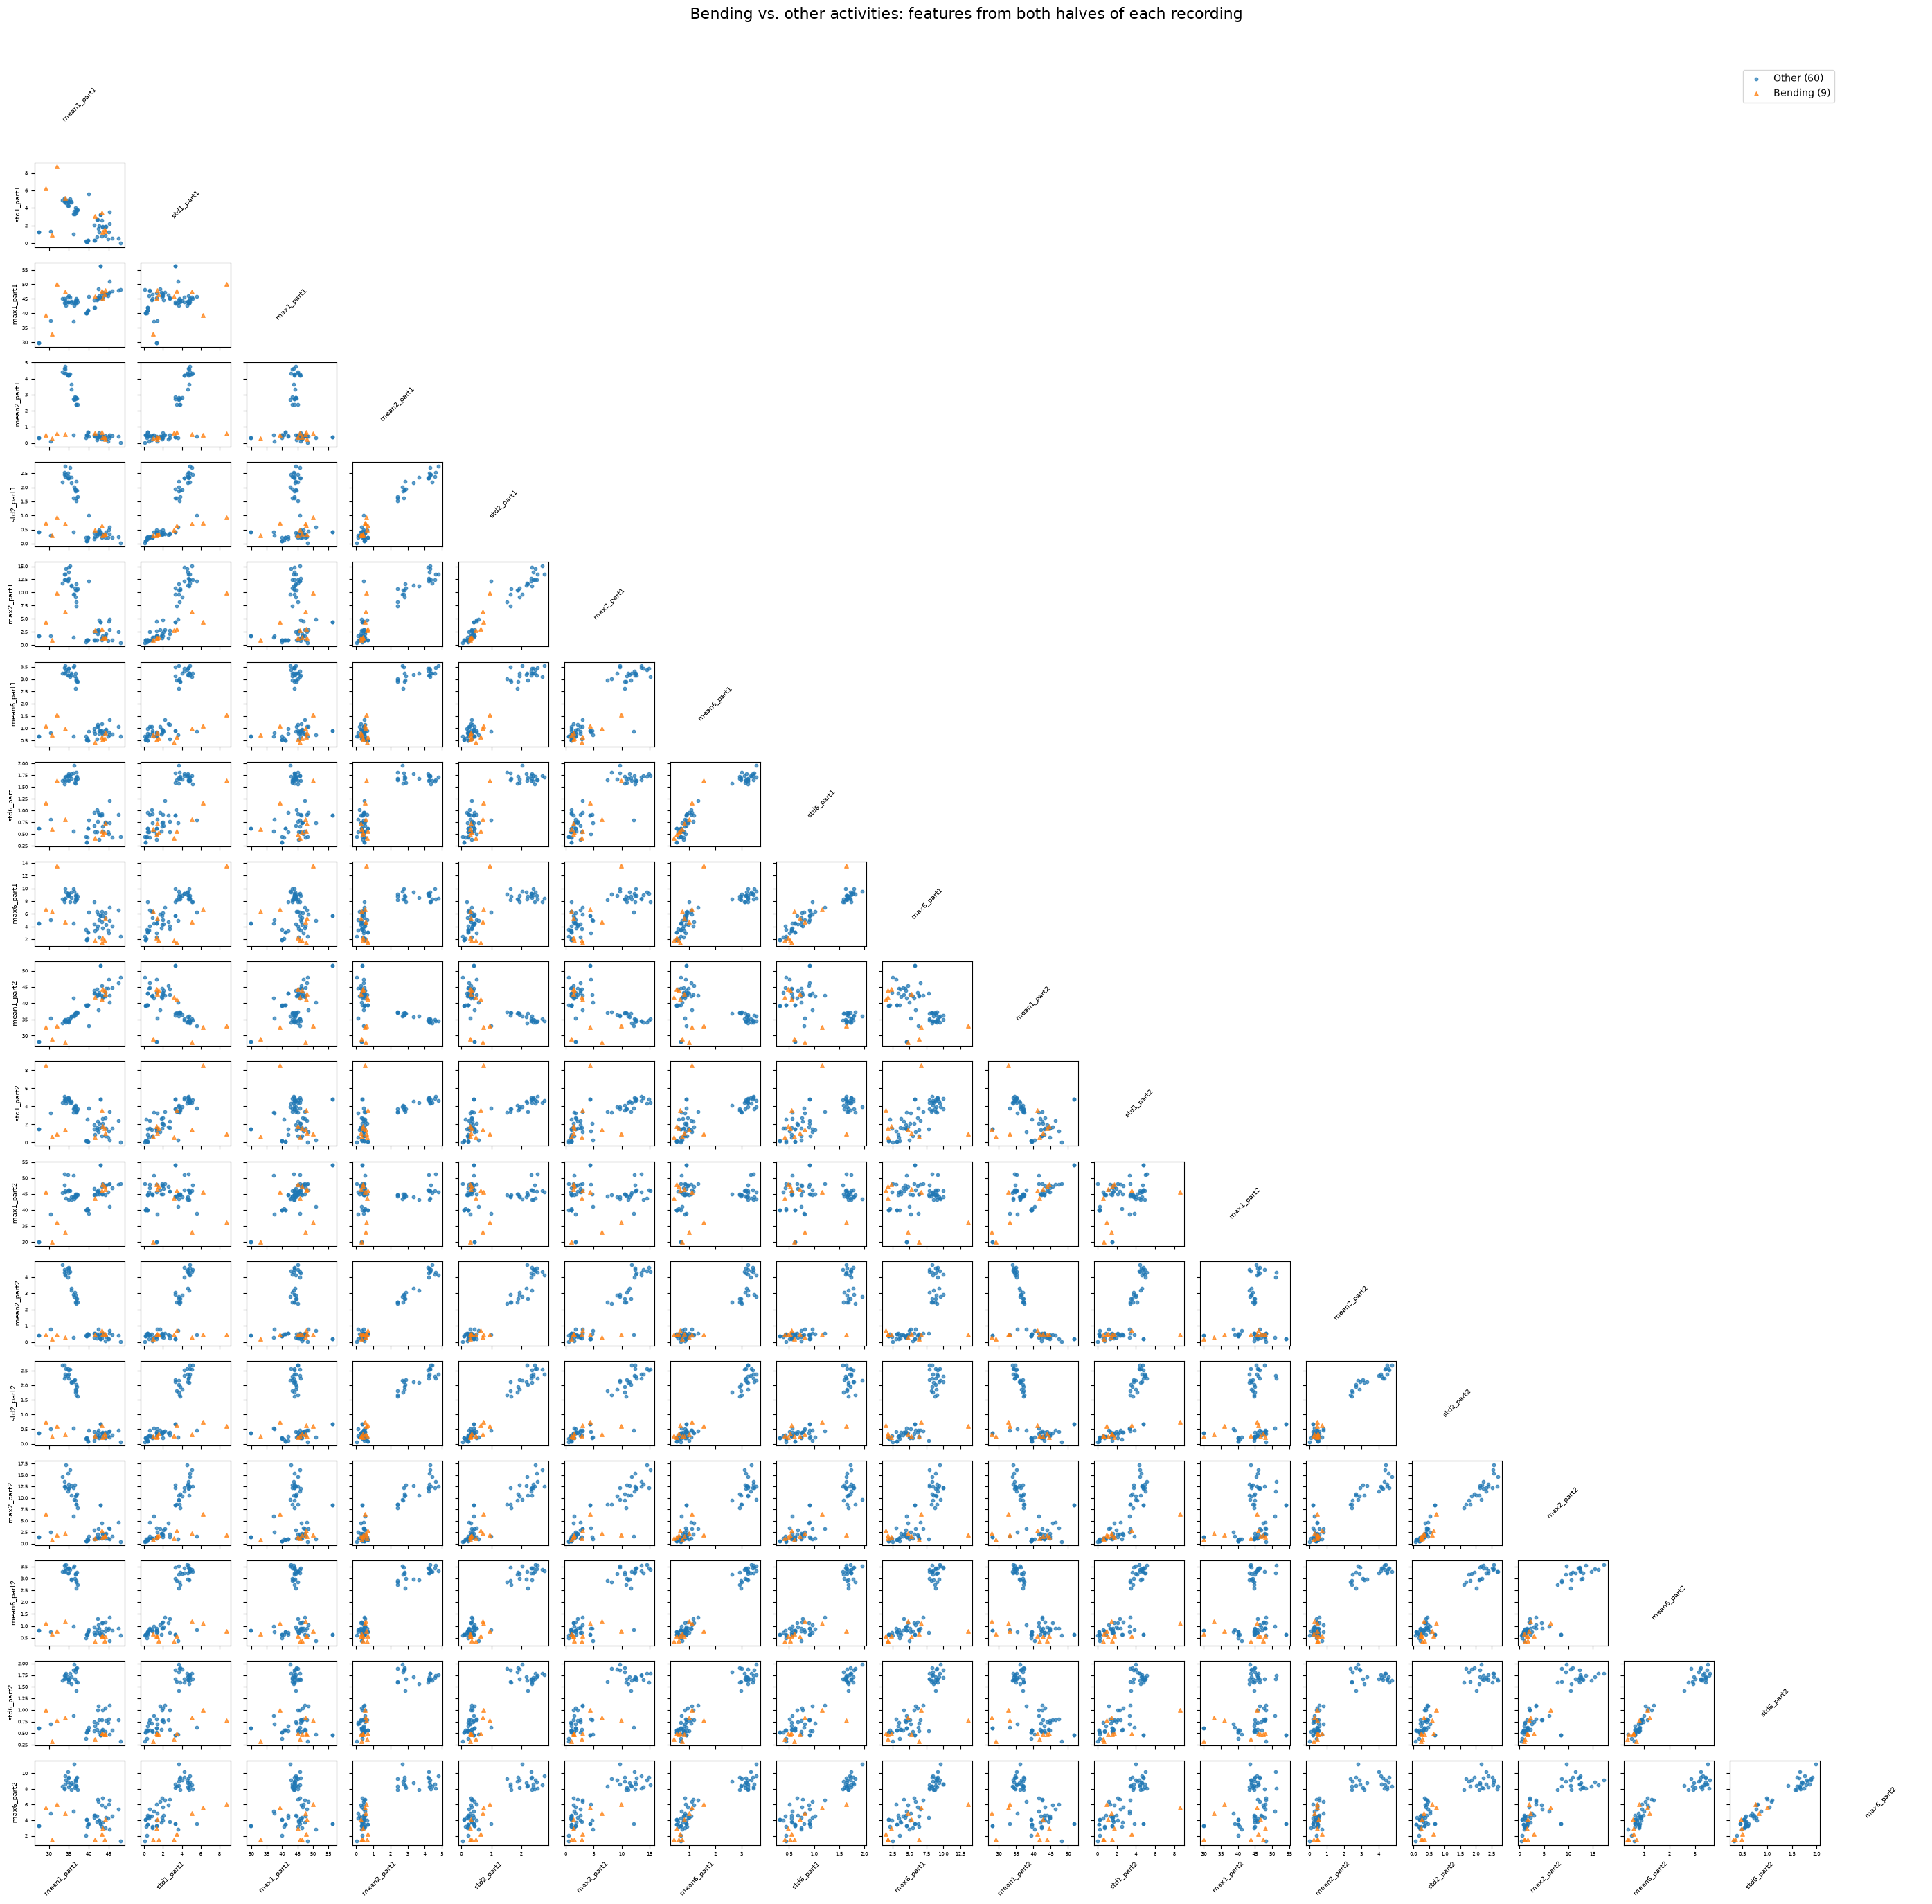

In [9]:
split_rows = []
split_lengths = []
for recording in train_recordings:
    parts = np.array_split(recording["data"].to_numpy(), 2)
    split_lengths.append([len(part) for part in parts])
    row_features = {}
    for part_number, part in enumerate(parts, start=1):
        for sensor in [1, 2, 6]:
            series = part[:, sensor]
            row_features.update({
                f"mean{sensor}_part{part_number}": series.mean(),
                f"std{sensor}_part{part_number}": series.std(ddof=1),
                f"max{sensor}_part{part_number}": series.max()
            })
    split_rows.append(row_features)

split_features = pd.DataFrame(split_rows, index=train_features.index)
split_is_bending = recording_info.loc[split_features.index, "activity"].isin(["bending1", "bending2"])
assert np.isfinite(split_features.to_numpy()).all()

split_columns = split_features.columns.tolist()
fig_halves, axes_halves = plt.subplots(18, 18, figsize=(28, 28))
for row, y_feature in enumerate(split_columns):
    for column, x_feature in enumerate(split_columns):
        ax = axes_halves[row, column]
        if row <= column:
            ax.set_axis_off()
            if row == column:
                ax.text(0.5, 0.5, x_feature, ha="center", va="center",
                        transform=ax.transAxes, fontsize=7, rotation=45)
            continue
        for bending, color, marker, label in [(False, "tab:blue", "o", "Other (60)"),
                                               (True, "tab:orange", "^", "Bending (9)")]:
            mask = split_is_bending == bending
            ax.scatter(split_features.loc[mask, x_feature], split_features.loc[mask, y_feature],
                       color=color, marker=marker, s=16 if bending else 10, alpha=0.7, label=label)
        ax.tick_params(labelsize=5, labelbottom=row == 17, labelleft=column == 0)
        if row == 17:
            ax.set_xlabel(x_feature, fontsize=7, rotation=45, ha="right")
        if column == 0:
            ax.set_ylabel(y_feature, fontsize=7)
handles, labels = axes_halves[1, 0].get_legend_handles_labels()
fig_halves.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.95, 0.95))
fig_halves.suptitle("Bending vs. other activities: features from both halves of each recording", fontsize=16)
fig_halves.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


There is no clear overall improvement in visual separation compared with Part (i). Splitting has let to some changes within recordings, but bending and other activities still overlap in many pairs.


#### iii. Time Series Segments

,segments,candidate_features,selected_features,mean_cv_accuracy
0,1,42,8,0.985714
1,2,84,7,0.971429
2,3,126,4,0.942857
3,4,168,15,0.957143
4,5,210,11,0.956044
5,6,252,41,0.971429
6,7,294,7,0.942857
7,8,336,14,0.942857
8,9,378,4,0.941758
9,10,420,18,0.985714


,segments,selected_features,mean_cv_accuracy,majority_baseline
0,1,8,0.985714,0.869565


,segments,p,mean_cv_accuracy
0,1,8,0.985714
1,1,9,0.985714
2,1,10,0.985714
3,20,10,0.985714
4,19,11,0.985714
5,20,11,0.985714
6,20,12,0.985714
7,20,13,0.985714
8,20,14,0.985714
9,20,15,0.985714


,Selected feature
0,3rd_quart1_part1
1,3rd_quart3_part1
2,max4_part1
3,1st_quart4_part1
4,min5_part1
5,max5_part1
6,mean5_part1
7,1st_quart6_part1


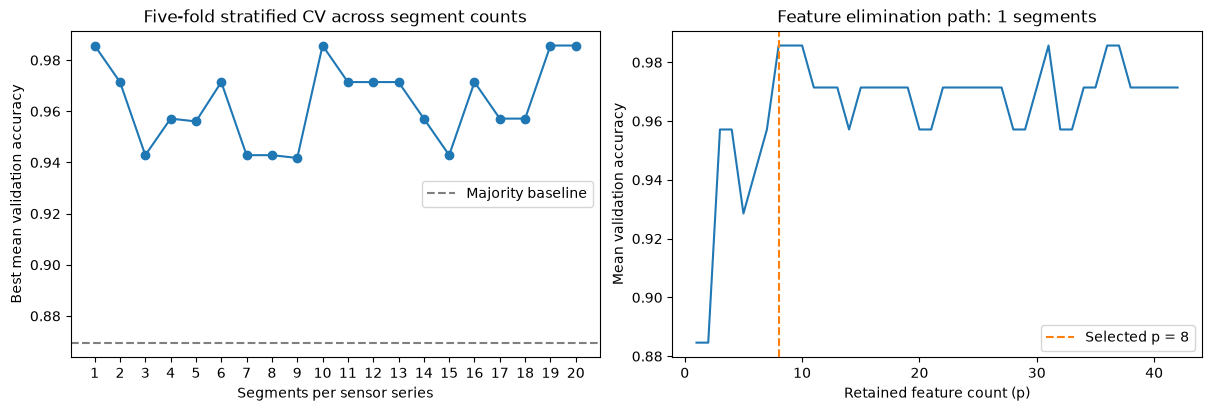

,mean_cv_accuracy,largest_coefficient,converged_folds
Iteration limit,,,
2,0.941758,2.413593,0
3,0.971429,3.386353,0
5,0.971429,5.825078,0
10,0.941758,19.780271,0


Tied limits       [3, 5]
Selected limit         3
dtype: object

0    Maximum Likelihood optimization failed to conv...
Name: Captured fitting warnings, dtype: str

In [10]:
def extract_segment_features(recording_list, segments, instance_index):
    rows = []
    for recording in recording_list:
        row = {}
        parts = np.array_split(recording["data"].to_numpy(), segments)
        for part_number, part in enumerate(parts, start=1):
            for sensor in range(1, 7):
                series = part[:, sensor]
                q1, q3 = np.quantile(series, [0.25, 0.75])
                row.update({
                    f"min{sensor}_part{part_number}": series.min(),
                    f"max{sensor}_part{part_number}": series.max(),
                    f"mean{sensor}_part{part_number}": series.mean(),
                    f"median{sensor}_part{part_number}": np.median(series),
                    f"std{sensor}_part{part_number}": series.std(ddof=1),
                    f"1st_quart{sensor}_part{part_number}": q1,
                    f"3rd_quart{sensor}_part{part_number}": q3
                })
        rows.append(row)
    return pd.DataFrame(rows, index=instance_index)


y_train = recording_info.loc[train_features.index, "activity"].isin(["bending1", "bending2"]).astype(int)
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
binary_folds = list(binary_cv.split(train_features, y_train))
assert y_train.value_counts().to_dict() == {0: 60, 1: 9}

segment_features = {}
rfe_models = {}
cv_tables = []
search_rows = []

with threadpool_limits(limits=1):
    for segments in range(1, 21):
        X = extract_segment_features(train_recordings, segments, train_features.index)
        assert np.isfinite(X.to_numpy()).all()
        segment_features[segments] = X

        estimator = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(C=np.inf, solver="lbfgs", max_iter=3000))
        ])
        selector = RFECV(estimator, step=1, min_features_to_select=1,
                         cv=binary_folds, scoring="accuracy", n_jobs=1,
                         importance_getter="named_steps.logistic.coef_")
        selector.fit(X, y_train)
        rfe_models[segments] = selector
        scores = pd.DataFrame({
            "segments": segments,
            "p": np.arange(1, X.shape[1] + 1),
            "mean_cv_accuracy": selector.cv_results_["mean_test_score"],
            "cv_std": selector.cv_results_["std_test_score"]
        })
        cv_tables.append(scores)
        search_rows.append({
            "segments": segments,
            "candidate_features": X.shape[1],
            "selected_features": selector.n_features_,
            "mean_cv_accuracy": scores["mean_cv_accuracy"].max()
        })

cv_results = pd.concat(cv_tables, ignore_index=True)
search_summary = pd.DataFrame(search_rows)
best_cv_accuracy = cv_results["mean_cv_accuracy"].max()
tied_best = cv_results.loc[
    np.isclose(cv_results["mean_cv_accuracy"], best_cv_accuracy, rtol=0, atol=1e-12)
].sort_values(["p", "segments"]).reset_index(drop=True)
best_segments = int(tied_best.loc[0, "segments"])
best_p = int(tied_best.loc[0, "p"])
best_rfe = rfe_models[best_segments]
best_train_features = segment_features[best_segments]
selected_feature_names = best_train_features.columns[best_rfe.support_].tolist()
selected_train_features = best_train_features[selected_feature_names]
majority_baseline = y_train.value_counts().max() / len(y_train)
best_settings = pd.DataFrame([{
    "segments": best_segments,
    "selected_features": best_p,
    "mean_cv_accuracy": best_cv_accuracy,
    "majority_baseline": majority_baseline
}])

display(search_summary)
display(best_settings)
with pd.option_context("display.max_rows", None):
    display(tied_best[["segments", "p", "mean_cv_accuracy"]])
display(pd.DataFrame({"Selected feature": selected_feature_names}))

fig_search, axes_search = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes_search[0].plot(search_summary["segments"], search_summary["mean_cv_accuracy"], marker="o")
axes_search[0].axhline(majority_baseline, color="gray", linestyle="--", label="Majority baseline")
axes_search[0].set_xticks(range(1, 21))
axes_search[0].set_xlabel("Segments per sensor series")
axes_search[0].set_ylabel("Best mean validation accuracy")
axes_search[0].set_title("Five-fold stratified CV across segment counts")
axes_search[0].legend()
selected_curve = cv_results.loc[cv_results["segments"] == best_segments]
axes_search[1].plot(selected_curve["p"], selected_curve["mean_cv_accuracy"])
axes_search[1].axvline(best_p, color="tab:orange", linestyle="--", label=f"Selected p = {best_p}")
axes_search[1].set_xlabel("Retained feature count (p)")
axes_search[1].set_ylabel("Mean validation accuracy")
axes_search[1].set_title(f"Feature elimination path: {best_segments} segments")
axes_search[1].legend()
plt.show()

# Compare stopping limits after choosing the segment and feature counts.
iteration_limits = [2, 3, 5, 10]
iteration_rows = []
with threadpool_limits(limits=1):
    for fold, (fit_rows, validation_rows) in enumerate(binary_folds, start=1):
        fold_selector = RFE(best_rfe.estimator, n_features_to_select=best_p,
                            importance_getter="named_steps.logistic.coef_")
        fold_selector.fit(best_train_features.iloc[fit_rows], y_train.iloc[fit_rows])
        fold_scaler = fold_selector.estimator_.named_steps["scaler"]
        fold_train = sm.add_constant(fold_scaler.transform(
            best_train_features.iloc[fit_rows, fold_selector.support_].to_numpy()), has_constant="add")
        fold_validation = sm.add_constant(fold_scaler.transform(
            best_train_features.iloc[validation_rows, fold_selector.support_].to_numpy()), has_constant="add")
        for limit in iteration_limits:
            with warnings.catch_warnings(record=True) as fit_warnings:
                warnings.simplefilter("always")
                fold_result = sm.Logit(y_train.iloc[fit_rows].to_numpy(), fold_train).fit(
                    method="newton", maxiter=limit, disp=False)
            iteration_rows.append({
                "Iteration limit": limit, "Fold": fold,
                "Validation accuracy": accuracy_score(y_train.iloc[validation_rows],
                                                       fold_result.predict(fold_validation) >= 0.5),
                "Largest absolute coefficient": np.abs(fold_result.params).max(),
                "Converged": fold_result.mle_retvals["converged"],
                "Warnings": "; ".join(sorted({str(w.message) for w in fit_warnings}))
            })
iteration_results = pd.DataFrame(iteration_rows)
iteration_summary = iteration_results.groupby("Iteration limit").agg(
    mean_cv_accuracy=("Validation accuracy", "mean"),
    largest_coefficient=("Largest absolute coefficient", "max"),
    converged_folds=("Converged", "sum"))
stopped_cv_accuracy = iteration_summary["mean_cv_accuracy"].max()
iteration_ties = iteration_summary.index[np.isclose(
    iteration_summary["mean_cv_accuracy"], stopped_cv_accuracy, rtol=0, atol=1e-12)].tolist()
best_max_iter = min(iteration_ties)
display(iteration_summary)
display(pd.Series({"Tied limits": iteration_ties, "Selected limit": best_max_iter}))
display(iteration_results["Warnings"].drop_duplicates().rename("Captured fitting warnings"))


I implemented RFE using the example listed in the homework document. Also, I implemented five-fold stratified CV to evaluate each retained feature count, with both binary classes represented in each fold.

The correct approach fits scaling and feature elimination within each training fold. Selecting features or fitting scaling before forming validation folds would leak information. Fixed statistics calculated independently for each recording can be extracted beforehand. C = infinity removes the regularization penalty. Among tied settings, I chose the fewest features, then the fewest segments, giving one segment and eight features.

Nineteen pairs tie at 98.57% mean CV accuracy.

After choosing the segment and feature counts, I chose to compare 2, 3, 5, and 10 Newton iterations using the same training folds. Scaling and RFE are refitted inside each fold. Limits 3 and 5 were tied at 97.14%. I chose the smaller limit (3). This is the final stopped classifier's tuning score, distinct from the RFE search score above. Both stages reuse the training folds, so neither score is an independent estimate of generalization. The test set and p-values do not determine the stopping limit. Non-convergence is expected because we deliberately stop early, as suggested in footnote 5 mentioned in the Homework pdf.


#### iv. Confusion Matrix

,Training accuracy,Training ROC AUC
0,1.0,1.0


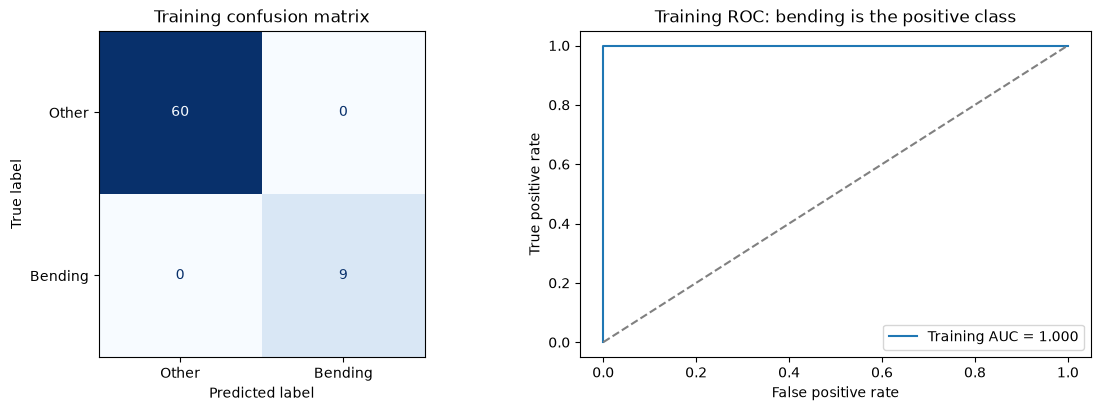

,Coefficient (standardized inputs),Coefficient (original inputs),Standard error (standardized inputs),Numerical Wald p-value
Parameter,,,,
const,-3.332930,-5.059420,0.894580,0.000195
3rd_quart1_part1,-0.684613,-0.144164,0.882419,0.437846
3rd_quart3_part1,-0.798824,-0.203921,1.197334,0.504664
max4_part1,1.184806,0.518364,1.531938,0.439284
1st_quart4_part1,-1.589046,-1.899314,3.087695,0.606806
min5_part1,1.269515,0.238195,1.915586,0.507504
max5_part1,1.683985,0.311267,1.398416,0.228509
mean5_part1,0.382330,0.075213,2.353352,0.870942
1st_quart6_part1,-0.564217,-0.734082,3.047533,0.853120


Complete separation                                                 True
Iteration limit                                                        3
Iterations used                                                        3
Converged                                                          False
Warnings               Maximum Likelihood optimization failed to conv...
Name: Stopped fit status, dtype: object

In [11]:
selected_scaler = best_rfe.estimator_.named_steps["scaler"]
binary_train_design = sm.add_constant(pd.DataFrame(
    selected_scaler.transform(selected_train_features.to_numpy()),
    index=y_train.index, columns=selected_feature_names), has_constant="add")
with warnings.catch_warnings(record=True) as binary_warnings:
    warnings.simplefilter("always")
    binary_result = sm.Logit(y_train, binary_train_design).fit(
        method="newton", maxiter=best_max_iter, disp=False)
train_probabilities = np.asarray(binary_result.predict(binary_train_design))
train_predictions = (train_probabilities >= 0.5).astype(int)
train_confusion = confusion_matrix(y_train, train_predictions, labels=[0, 1])
train_auc = roc_auc_score(y_train, train_probabilities)
training_metrics = pd.DataFrame([{
    "Training accuracy": accuracy_score(y_train, train_predictions),
    "Training ROC AUC": train_auc
}])
display(training_metrics)

fig_training, axes_training = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ConfusionMatrixDisplay(train_confusion, display_labels=["Other", "Bending"]).plot(
    ax=axes_training[0], cmap="Blues", colorbar=False)
axes_training[0].set_title("Training confusion matrix")
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, train_probabilities, pos_label=1)
axes_training[1].plot(fpr_train, tpr_train, label=f"Training AUC = {train_auc:.3f}")
axes_training[1].plot([0, 1], [0, 1], "--", color="gray")
axes_training[1].set_xlabel("False positive rate")
axes_training[1].set_ylabel("True positive rate")
axes_training[1].set_title("Training ROC: bending is the positive class")
axes_training[1].legend(loc="lower right")
plt.show()


original_coef = binary_result.params.iloc[1:].to_numpy() / selected_scaler.scale_
original_intercept = binary_result.params.iloc[0] - original_coef @ selected_scaler.mean_
coefficient_table = pd.DataFrame({
    "Coefficient (standardized inputs)": binary_result.params,
    "Coefficient (original inputs)": np.r_[original_intercept, original_coef],
    "Standard error (standardized inputs)": binary_result.bse,
    "Numerical Wald p-value": binary_result.pvalues
})
coefficient_table.index.name = "Parameter"
# The RFE fit supplies a separating direction for the selected features.
signed_margins = (2 * y_train.to_numpy() - 1) * best_rfe.decision_function(best_train_features)
complete_separation = bool(np.all(signed_margins > 0))
inference_diagnostics = pd.Series({
    "Complete separation": complete_separation,
    "Iteration limit": best_max_iter,
    "Iterations used": binary_result.mle_retvals["iterations"],
    "Converged": binary_result.mle_retvals["converged"],
    "Warnings": "; ".join(str(w.message) for w in binary_warnings)
}, name="Stopped fit status")
display(coefficient_table)
display(inference_diagnostics)


The coefficients, standard errors, numerical Wald p-values, and predictions all come from the same unpenalized Statsmodels fit, stopped after three Newton iterations. Statsmodels Logit uses no regularization here. The eight features admit complete separation, so the finite coefficients are stopping values rather than finite maximum-likelihood estimates. The numerical p-values are reported as requested, but are unreliable under separation and are not used for feature selection or significance claims.

The stopped model correctly classifies all 69 training recordings, with training AUC 1.00.


#### v. Test Classifier

,Mean CV accuracy,Test accuracy,Test minus CV accuracy,Test ROC AUC
0,0.971429,1.0,0.028571,1.0


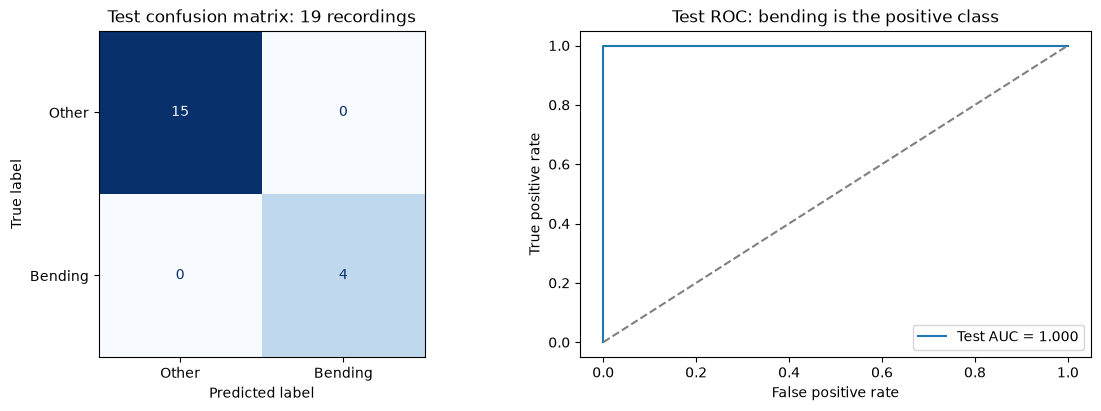

In [12]:
segmented_test_features = extract_segment_features(test_recordings, best_segments, test_features.index)
assert segmented_test_features.columns.equals(best_train_features.columns)
assert np.isfinite(segmented_test_features.to_numpy()).all()
selected_test_features = segmented_test_features[selected_feature_names]
y_test = recording_info.loc[segmented_test_features.index, "activity"].isin(["bending1", "bending2"]).astype(int)

binary_test_design = sm.add_constant(pd.DataFrame(
    selected_scaler.transform(selected_test_features.to_numpy()),
    index=y_test.index, columns=selected_feature_names), has_constant="add")
test_probabilities = np.asarray(binary_result.predict(binary_test_design))
test_predictions = (test_probabilities >= 0.5).astype(int)
test_accuracy = accuracy_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)
test_confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
comparison_metrics = pd.DataFrame([{
    "Mean CV accuracy": stopped_cv_accuracy,
    "Test accuracy": test_accuracy,
    "Test minus CV accuracy": test_accuracy - stopped_cv_accuracy,
    "Test ROC AUC": test_auc
}])
display(comparison_metrics)

fig_test, axes_test = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ConfusionMatrixDisplay(test_confusion, display_labels=["Other", "Bending"]).plot(
    ax=axes_test[0], cmap="Blues", colorbar=False)
axes_test[0].set_title("Test confusion matrix: 19 recordings")
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, test_probabilities, pos_label=1)
axes_test[1].plot(fpr_test, tpr_test, label=f"Test AUC = {test_auc:.3f}")
axes_test[1].plot([0, 1], [0, 1], "--", color="gray")
axes_test[1].set_xlabel("False positive rate")
axes_test[1].set_ylabel("True positive rate")
axes_test[1].set_title("Test ROC: bending is the positive class")
axes_test[1].legend(loc="lower right")
plt.show()


The test recordings use the selected segmentation, feature subset, training-fitted scaler, and three-iteration fit. The table compares test accuracy with the stopped classifier's 97.14% mean validation accuracy. This CV score was used during tuning. One test error changes accuracy by about 5.26 percentage points.

Test accuracy is 100% (19/19), compared with 97.14% mean validation accuracy, and the test AUC is 1.00.


#### vi. Separation

Yes, the eight selected features seem to completely separate the training classes. Hence, we can conclude that unpenalized logistic regression has no finite maximum-likelihood estimate. Following footnote 5, we stop the final fit early, using three iterations selected by training-only cross-validation. This keeps the fitted values finite, but does not make the reported numerical p-values reliable significance tests.


#### vii. Imbalance

Yes, I can see imabalanced training classes from the confusion matrices. 60 recordings are non-bending and only 9 are bending. To address this, we use case-control sampling, keeping all 60 non-bending recordings and sampling bending recordings with replacement to obtain 60 bending examples. We then refit logistic regression and adjust its intercept for the changed class proportions.

,Other,Bending
Original training recordings,60,9
Case-control training sample,60,60


,Original training bending proportion,Sampled bending proportion,Intercept shift,Iteration limit,Converged,Warnings
0,0.130435,0.5,-1.89712,3,False,Maximum Likelihood optimization failed to conv...


,Before intercept adjustment,After intercept adjustment
Parameter (standardized inputs),,
Intercept,-3.106615,-5.003735
3rd_quart1_part1,-0.792637,-0.792637
3rd_quart3_part1,-1.000527,-1.000527
max4_part1,1.373206,1.373206
1st_quart4_part1,-2.112558,-2.112558
min5_part1,1.645862,1.645862
max5_part1,1.794372,1.794372
mean5_part1,0.260677,0.260677
1st_quart6_part1,-0.587314,-0.587314


,Model,Dataset,Accuracy,Balanced accuracy,Bending recall,ROC AUC
0,Original,Training (69),1.000000,1.000,1.00,1.0
1,"Case-control, adjusted",Training (69),1.000000,1.000,1.00,1.0
2,Original,Test (19),1.000000,1.000,1.00,1.0
3,"Case-control, adjusted",Test (19),0.947368,0.875,0.75,1.0


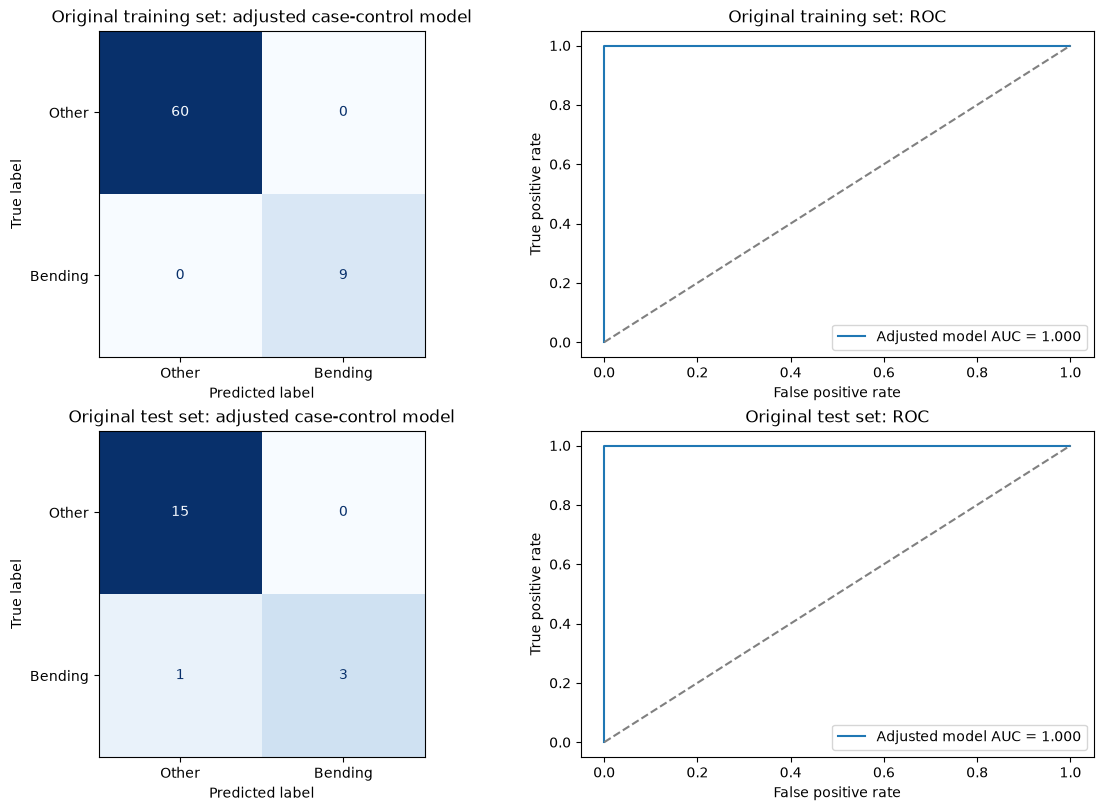

In [13]:
case_train_scaled = selected_scaler.transform(selected_train_features.to_numpy())
case_test_scaled = selected_scaler.transform(selected_test_features.to_numpy())
control_positions = np.flatnonzero(y_train.to_numpy() == 0)
case_positions = np.flatnonzero(y_train.to_numpy() == 1)
case_rng = np.random.default_rng(42)
sampled_case_positions = case_rng.choice(case_positions, size=len(control_positions), replace=True)
case_control_positions = np.r_[control_positions, sampled_case_positions]
case_rng.shuffle(case_control_positions)
case_control_X = case_train_scaled[case_control_positions]
case_control_y = y_train.to_numpy()[case_control_positions]
assert np.bincount(case_control_y).tolist() == [60, 60]

class_counts = pd.DataFrame({
    "Other": [len(control_positions), np.sum(case_control_y == 0)],
    "Bending": [len(case_positions), np.sum(case_control_y == 1)]
}, index=["Original training recordings", "Case-control training sample"])
display(class_counts)

case_control_design = sm.add_constant(case_control_X, has_constant="add")
with warnings.catch_warnings(record=True) as case_warnings:
    warnings.simplefilter("always")
    case_result = sm.Logit(case_control_y, case_control_design).fit(
        method="newton", maxiter=best_max_iter, disp=False)
case_params_before = case_result.params.copy()
case_params_adjusted = case_params_before.copy()

original_prevalence = y_train.mean()
sampled_prevalence = case_control_y.mean()
intercept_shift = (np.log(original_prevalence / (1 - original_prevalence))
                   - np.log(sampled_prevalence / (1 - sampled_prevalence)))
case_params_adjusted[0] += intercept_shift
sampling_adjustment = pd.DataFrame([{
    "Original training bending proportion": original_prevalence,
    "Sampled bending proportion": sampled_prevalence,
    "Intercept shift": intercept_shift,
    "Iteration limit": best_max_iter,
    "Converged": case_result.mle_retvals["converged"],
    "Warnings": "; ".join(str(w.message) for w in case_warnings)
}])
case_coefficient_table = pd.DataFrame({
    "Before intercept adjustment": case_params_before,
    "After intercept adjustment": case_params_adjusted
}, index=["Intercept"] + selected_feature_names)
case_coefficient_table.index.name = "Parameter (standardized inputs)"
display(sampling_adjustment)
display(case_coefficient_table)

case_train_probabilities = case_result.model.predict(case_params_adjusted, binary_train_design)
case_test_probabilities = case_result.model.predict(case_params_adjusted, binary_test_design)
case_train_predictions = (case_train_probabilities >= 0.5).astype(int)
case_test_predictions = (case_test_probabilities >= 0.5).astype(int)
case_metrics_rows = []
for model_name, dataset, truth, predictions, probabilities in [
    ("Original", "Training (69)", y_train, train_predictions, train_probabilities),
    ("Case-control, adjusted", "Training (69)", y_train, case_train_predictions, case_train_probabilities),
    ("Original", "Test (19)", y_test, test_predictions, test_probabilities),
    ("Case-control, adjusted", "Test (19)", y_test, case_test_predictions, case_test_probabilities)
]:
    case_metrics_rows.append({
        "Model": model_name, "Dataset": dataset,
        "Accuracy": accuracy_score(truth, predictions),
        "Balanced accuracy": balanced_accuracy_score(truth, predictions),
        "Bending recall": recall_score(truth, predictions, pos_label=1),
        "ROC AUC": roc_auc_score(truth, probabilities)
    })
case_metrics = pd.DataFrame(case_metrics_rows)
display(case_metrics)

fig_case, axes_case = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for row, dataset, truth, predictions, probabilities in [
    (0, "Original training set", y_train, case_train_predictions, case_train_probabilities),
    (1, "Original test set", y_test, case_test_predictions, case_test_probabilities)
]:
    cm = confusion_matrix(truth, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Other", "Bending"]).plot(
        ax=axes_case[row, 0], cmap="Blues", colorbar=False)
    axes_case[row, 0].set_title(f"{dataset}: adjusted case-control model")
    fpr, tpr, _ = roc_curve(truth, probabilities, pos_label=1)
    area = roc_auc_score(truth, probabilities)
    axes_case[row, 1].plot(fpr, tpr, label=f"Adjusted model AUC = {area:.3f}")
    axes_case[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes_case[row, 1].set_xlabel("False positive rate")
    axes_case[row, 1].set_ylabel("True positive rate")
    axes_case[row, 1].set_title(f"{dataset}: ROC")
    axes_case[row, 1].legend(loc="lower right")
plt.show()


The intercept is adjusted to account for the changed class proportions, and the model is evaluated on the original training and test sets.

The adjusted model correctly classifies all training recordings and 18/19 test recordings. It misses one bending recording, giving test bending recall 0.75. Test AUC remains 1.00 because the probability ranking is correct, even though one bending probability falls below the 0.5 threshold.


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

0      0.001000
1      0.003594
2      0.012915
3      0.046416
4      0.166810
5      0.599484
6      2.154435
7      7.742637
8     27.825594
9    100.000000
Name: Candidate C values, dtype: float64

,segments,C,mean_cv_accuracy,cv_std
0,1,0.599484,0.957143,0.057143
1,2,0.599484,0.957143,0.057143
2,3,0.599484,0.971429,0.034993
3,4,0.599484,0.957143,0.034993
4,5,7.742637,0.941758,0.029199
5,6,2.154435,0.957143,0.034993
6,7,0.599484,0.927473,0.045229
7,8,2.154435,0.928571,0.045175
8,9,0.599484,0.927473,0.045229
9,10,100.000000,0.971429,0.034993


,segments,C,candidate_features,nonzero_features,mean_cv_accuracy,Selected C at grid boundary
0,12,0.599484,504,7,0.985714,False


,segments,C,mean_cv_accuracy
0,12,0.599484,0.985714
1,19,0.599484,0.985714


,Coefficient (standardized inputs),Coefficient (original inputs)
Retained parameter,,
Intercept,-2.598391,-2.192010
median5_part2,0.121449,0.018907
1st_quart5_part2,1.690046,0.263067
max1_part7,-0.542940,-0.100652
median4_part9,-0.004611,-0.004015
3rd_quart4_part9,-0.039819,-0.026161
min5_part11,0.384445,0.060432
max6_part11,-0.309380,-0.118386


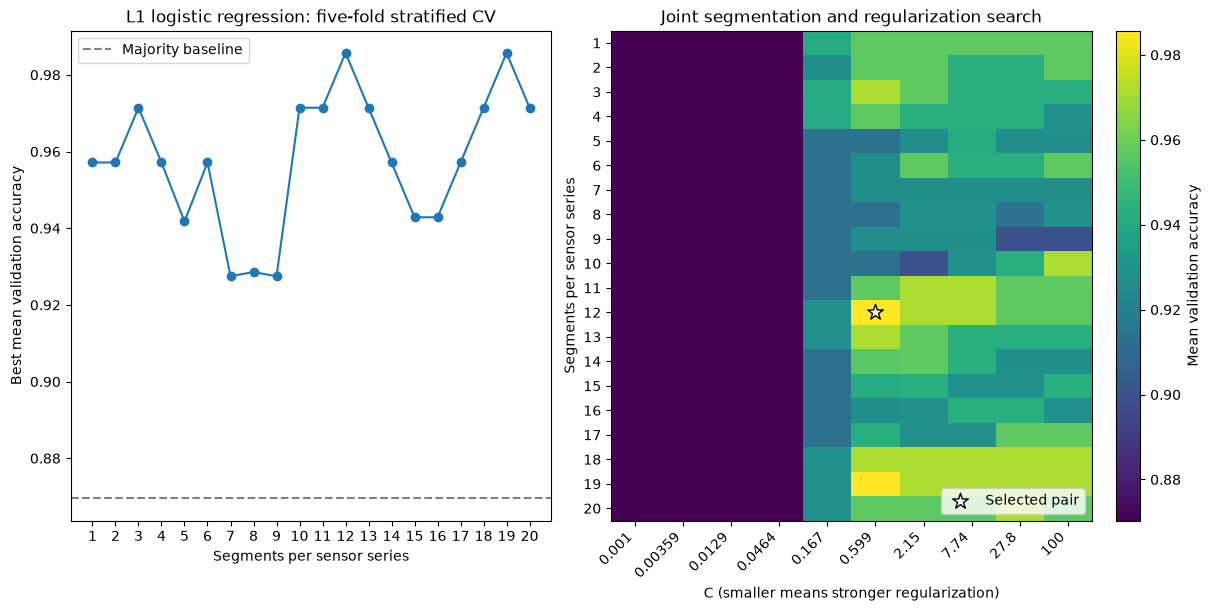

,Dataset,Accuracy,Balanced accuracy,Bending recall,ROC AUC
0,Training (69),1.000000,1.000,1.00,1.0
1,Test (19),0.947368,0.875,0.75,1.0


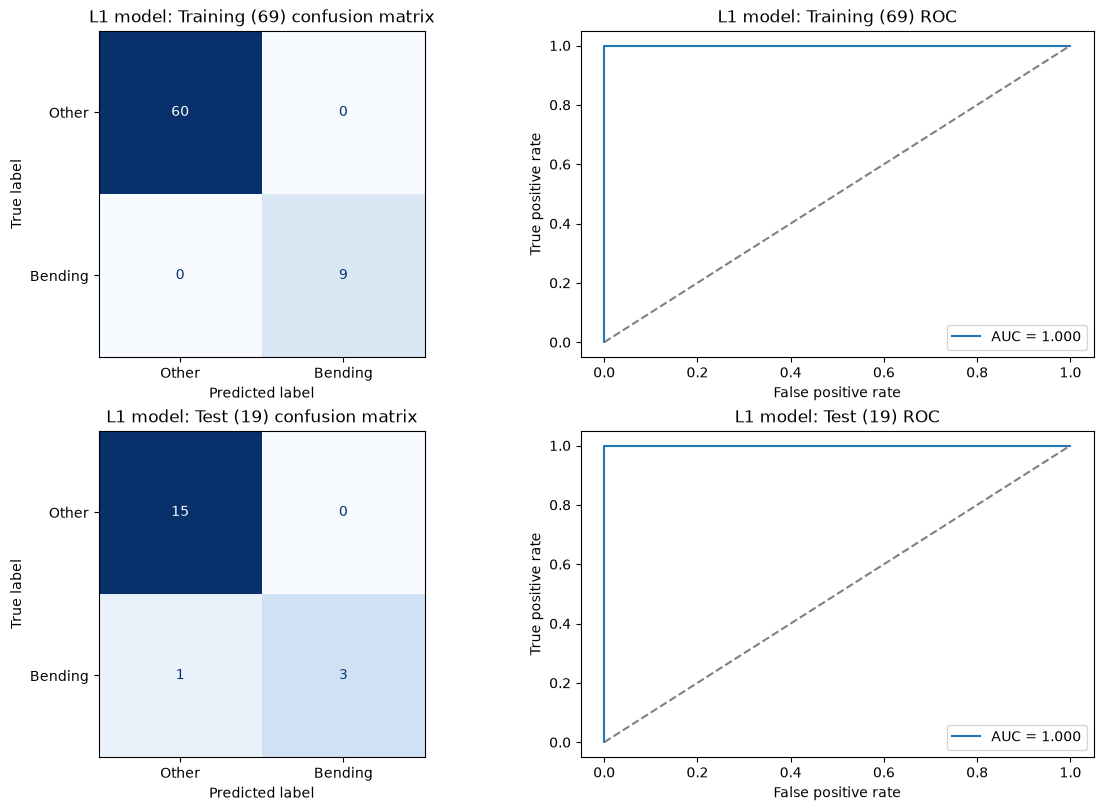

In [14]:
l1_C_values = np.logspace(-3, 2, 10)
l1_cv_tables = []

with threadpool_limits(limits=1):
    for segments in range(1, 21):
        X_l1 = segment_features[segments]
        l1_estimator = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=10000,
                                             intercept_scaling=1, random_state=42))
        ])
        l1_search = GridSearchCV(l1_estimator, {"logistic__C": l1_C_values},
                                cv=binary_folds, scoring="accuracy", refit=False,
                                n_jobs=1, error_score="raise")
        l1_search.fit(X_l1, y_train)
        l1_cv_tables.append(pd.DataFrame({
            "segments": segments,
            "C": np.asarray(l1_search.cv_results_["param_logistic__C"], dtype=float),
            "mean_cv_accuracy": l1_search.cv_results_["mean_test_score"],
            "cv_std": l1_search.cv_results_["std_test_score"]
        }))

l1_cv_results = pd.concat(l1_cv_tables, ignore_index=True)
l1_best_cv_accuracy = l1_cv_results["mean_cv_accuracy"].max()
l1_tied_best = l1_cv_results.loc[
    np.isclose(l1_cv_results["mean_cv_accuracy"], l1_best_cv_accuracy, rtol=0, atol=1e-12)
].sort_values(["segments", "C"]).reset_index(drop=True)
l1_best_segments = int(l1_tied_best.loc[0, "segments"])
l1_best_C = float(l1_tied_best.loc[0, "C"])
l1_segment_summary = (l1_cv_results.sort_values(["segments", "mean_cv_accuracy", "C"],
                                               ascending=[True, False, True])
                      .groupby("segments", sort=False).head(1).reset_index(drop=True))

l1_train_features = segment_features[l1_best_segments]
best_l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(C=l1_best_C, l1_ratio=1, solver="liblinear", max_iter=10000,
                                     intercept_scaling=1, random_state=42))
])
with threadpool_limits(limits=1):
    best_l1_model.fit(l1_train_features, y_train)
l1_scaler = best_l1_model.named_steps["scaler"]
l1_logistic = best_l1_model.named_steps["logistic"]
l1_nonzero_mask = l1_logistic.coef_[0] != 0
l1_selected_features = l1_train_features.columns[l1_nonzero_mask].tolist()
l1_original_coef = l1_logistic.coef_[0] / l1_scaler.scale_
l1_original_intercept = l1_logistic.intercept_[0] - l1_original_coef @ l1_scaler.mean_
l1_coefficient_table = pd.DataFrame({
    "Coefficient (standardized inputs)": np.r_[l1_logistic.intercept_[0], l1_logistic.coef_[0][l1_nonzero_mask]],
    "Coefficient (original inputs)": np.r_[l1_original_intercept, l1_original_coef[l1_nonzero_mask]]
}, index=["Intercept"] + l1_selected_features)
l1_coefficient_table.index.name = "Retained parameter"
l1_best_settings = pd.DataFrame([{
    "segments": l1_best_segments, "C": l1_best_C,
    "candidate_features": l1_train_features.shape[1],
    "nonzero_features": int(l1_nonzero_mask.sum()),
    "mean_cv_accuracy": l1_best_cv_accuracy,
    "Selected C at grid boundary": l1_best_C in [l1_C_values[0], l1_C_values[-1]]
}])
display(pd.Series(l1_C_values, name="Candidate C values"))
display(l1_segment_summary)
display(l1_best_settings)
with pd.option_context("display.max_rows", None):
    display(l1_tied_best[["segments", "C", "mean_cv_accuracy"]])
display(l1_coefficient_table)

fig_l1_search, axes_l1_search = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
axes_l1_search[0].plot(l1_segment_summary["segments"], l1_segment_summary["mean_cv_accuracy"], marker="o")
axes_l1_search[0].axhline(majority_baseline, color="gray", linestyle="--", label="Majority baseline")
axes_l1_search[0].set_xticks(range(1, 21))
axes_l1_search[0].set_xlabel("Segments per sensor series")
axes_l1_search[0].set_ylabel("Best mean validation accuracy")
axes_l1_search[0].set_title("L1 logistic regression: five-fold stratified CV")
axes_l1_search[0].legend()
l1_score_grid = l1_cv_results.pivot(index="segments", columns="C", values="mean_cv_accuracy")
image = axes_l1_search[1].imshow(l1_score_grid, aspect="auto", cmap="viridis")
axes_l1_search[1].set_xticks(range(10), [f"{value:.3g}" for value in l1_C_values], rotation=45, ha="right")
axes_l1_search[1].set_yticks(range(20), range(1, 21))
axes_l1_search[1].set_xlabel("C (smaller means stronger regularization)")
axes_l1_search[1].set_ylabel("Segments per sensor series")
axes_l1_search[1].set_title("Joint segmentation and regularization search")
selected_C_position = int(np.flatnonzero(np.isclose(l1_C_values, l1_best_C))[0])
axes_l1_search[1].scatter(selected_C_position, l1_best_segments - 1,
                          marker="*", s=140, color="white", edgecolors="black", label="Selected pair")
axes_l1_search[1].legend(loc="lower right")
fig_l1_search.colorbar(image, ax=axes_l1_search[1], label="Mean validation accuracy")
plt.show()

l1_test_features = extract_segment_features(test_recordings, l1_best_segments, test_features.index)
assert l1_test_features.columns.equals(l1_train_features.columns)
l1_train_predictions = best_l1_model.predict(l1_train_features)
l1_train_probabilities = best_l1_model.predict_proba(l1_train_features)[:, 1]
l1_test_predictions = best_l1_model.predict(l1_test_features)
l1_test_probabilities = best_l1_model.predict_proba(l1_test_features)[:, 1]
l1_metrics_rows = []
fig_l1_metrics, axes_l1_metrics = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for row, dataset, truth, predictions, probabilities in [
    (0, "Training (69)", y_train, l1_train_predictions, l1_train_probabilities),
    (1, "Test (19)", y_test, l1_test_predictions, l1_test_probabilities)
]:
    area = roc_auc_score(truth, probabilities)
    l1_metrics_rows.append({
        "Dataset": dataset, "Accuracy": accuracy_score(truth, predictions),
        "Balanced accuracy": balanced_accuracy_score(truth, predictions),
        "Bending recall": recall_score(truth, predictions, pos_label=1), "ROC AUC": area
    })
    cm = confusion_matrix(truth, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Other", "Bending"]).plot(
        ax=axes_l1_metrics[row, 0], cmap="Blues", colorbar=False)
    axes_l1_metrics[row, 0].set_title(f"L1 model: {dataset} confusion matrix")
    fpr, tpr, _ = roc_curve(truth, probabilities, pos_label=1)
    axes_l1_metrics[row, 1].plot(fpr, tpr, label=f"AUC = {area:.3f}")
    axes_l1_metrics[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes_l1_metrics[row, 1].set_xlabel("False positive rate")
    axes_l1_metrics[row, 1].set_ylabel("True positive rate")
    axes_l1_metrics[row, 1].set_title(f"L1 model: {dataset} ROC")
    axes_l1_metrics[row, 1].legend(loc="lower right")
l1_metrics = pd.DataFrame(l1_metrics_rows)
display(l1_metrics)
plt.show()


We search segment counts 1–20 and ten logarithmically spaced C values from 0.001 to 100. Smaller C gives stronger regularization. A pipeline fits scaling within each training fold. Liblinear fits the binary L1 model; its default synthetic intercept is also penalized. All tied best pairs are reported, with fewer segments preferred, then smaller C.

The selected pair is 12 segments and C = 0.599484, with seven nonzero features out of 504 and 98.57% mean CV accuracy. Nineteen segments with the same C ties, so we choose 12. The selected C is inside the grid. Training accuracy is 100% while the test accuracy is 94.74% (18/19). Test AUC is 1.00 because the probabilities rank bending above other activities, although one bending recording falls below the classification threshold.


#### ii. Comparison

The RFE feature search reaches 98.57% mean CV accuracy with one segment and eight features. The final early-stopped classifier reaches 97.14% during iteration-limit tuning. L1 reaches 98.57% with 12 segments and seven features.

I used the permitted RFE alternative to p-value pruning because of separation. Numerical p-values from the final stopped fit are reported but not used for selection. L1 is easier to implement because it fits coefficients and removes features together, whereas RFE repeatedly refits after removing features. It does not guarantee better test accuracy.

The stopped RFE model classifies 19/19 test recordings correctly, compared with 18/19 for L1. Both have test AUC 1.00, with RFE having a higher test accuracy on this split.


### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

activity,bending1,bending2,cycling,lying,sitting,standing,walking
Validation fold,,,,,,,
1,1,1,3,2,2,3,2
2,1,1,2,3,2,3,2
3,1,1,2,3,2,2,3
4,1,1,2,2,3,2,3
5,1,0,3,2,3,2,2


,segments,C,mean_cv_accuracy
0,1,2.154435,0.928571
1,2,7.742637,0.869231
2,3,100.000000,0.885714
3,4,100.000000,0.900000
4,5,27.825594,0.885714
5,6,100.000000,0.900000
6,7,100.000000,0.870330
7,8,100.000000,0.884615
8,9,7.742637,0.871429
9,10,27.825594,0.870330


,segments,C,mean_cv_accuracy,retained_features,Selected C at grid boundary
0,1,2.154435,0.928571,28,False


,segments,C,mean_cv_accuracy
0,1,2.154435,0.928571


,Dataset,Accuracy,Error,Macro OvR AUC
0,Training (69),0.985507,0.014493,1.000000
1,Test (19),0.894737,0.105263,0.994048


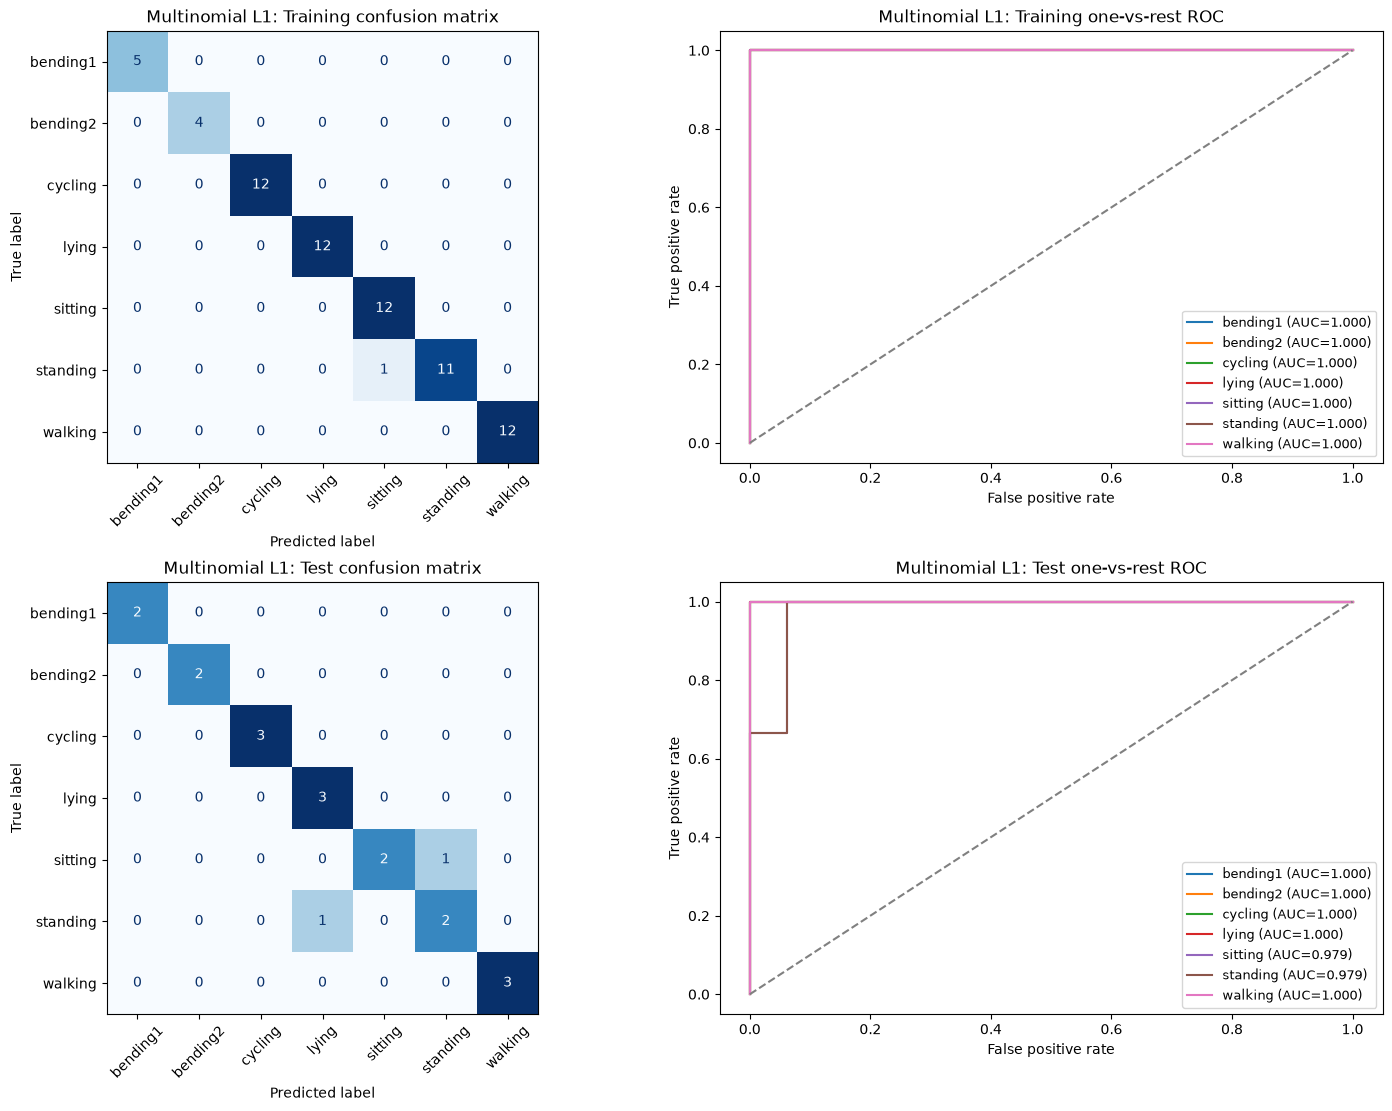

In [15]:
y_train_multi = recording_info.loc[train_features.index, "activity"]
y_test_multi = recording_info.loc[test_features.index, "activity"]
multi_classes = np.sort(y_train_multi.unique())
multi_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Capture the expected rare-class warning; the fold counts below document it.
with warnings.catch_warnings(record=True) as multi_split_warnings:
    warnings.simplefilter("always", UserWarning)
    multi_folds = list(multi_cv.split(train_features, y_train_multi))
multi_fold_counts = pd.DataFrame([
    y_train_multi.iloc[validation].value_counts().reindex(multi_classes, fill_value=0)
    for _, validation in multi_folds
], index=range(1, 6))
multi_fold_counts.index.name = "Validation fold"
display(multi_fold_counts)

multi_cv_tables = []
with threadpool_limits(limits=1):
    for segments in range(1, 21):
        estimator = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(l1_ratio=1, solver="saga", tol=1e-3,
                                             max_iter=10000, random_state=42))
        ])
        search = GridSearchCV(estimator, {"logistic__C": l1_C_values}, cv=multi_folds,
                              scoring="accuracy", refit=False, n_jobs=1, error_score="raise")
        search.fit(segment_features[segments], y_train_multi)
        multi_cv_tables.append(pd.DataFrame({
            "segments": segments,
            "C": np.asarray(search.cv_results_["param_logistic__C"], dtype=float),
            "mean_cv_accuracy": search.cv_results_["mean_test_score"]
        }))
multi_cv_results = pd.concat(multi_cv_tables, ignore_index=True)
multi_best_cv_accuracy = multi_cv_results["mean_cv_accuracy"].max()
multi_tied_best = multi_cv_results.loc[
    np.isclose(multi_cv_results["mean_cv_accuracy"], multi_best_cv_accuracy, rtol=0, atol=1e-12)
].sort_values(["segments", "C"]).reset_index(drop=True)
multi_best_segments = int(multi_tied_best.loc[0, "segments"])
multi_best_C = float(multi_tied_best.loc[0, "C"])
multi_segment_summary = (multi_cv_results.sort_values(
    ["segments", "mean_cv_accuracy", "C"], ascending=[True, False, True])
    .groupby("segments", sort=False).head(1).reset_index(drop=True))
multi_train_features = segment_features[multi_best_segments]
best_multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(C=multi_best_C, l1_ratio=1, solver="saga", tol=1e-3,
                                     max_iter=10000, random_state=42))
])
with threadpool_limits(limits=1):
    best_multi_model.fit(multi_train_features, y_train_multi)
multi_logistic = best_multi_model.named_steps["logistic"]
multi_best_settings = pd.DataFrame([{
    "segments": multi_best_segments, "C": multi_best_C,
    "mean_cv_accuracy": multi_best_cv_accuracy,
    "retained_features": np.any(multi_logistic.coef_ != 0, axis=0).sum(),
    "Selected C at grid boundary": multi_best_C in [l1_C_values[0], l1_C_values[-1]]
}])
display(multi_segment_summary)
display(multi_best_settings)
display(multi_tied_best)

multi_test_features = extract_segment_features(test_recordings, multi_best_segments, test_features.index)
assert multi_test_features.columns.equals(multi_train_features.columns)
multi_train_predictions = best_multi_model.predict(multi_train_features)
multi_train_probabilities = best_multi_model.predict_proba(multi_train_features)
multi_test_predictions = best_multi_model.predict(multi_test_features)
multi_test_probabilities = best_multi_model.predict_proba(multi_test_features)
multi_metrics = pd.DataFrame([
    {"Dataset": name, "Accuracy": accuracy_score(truth, prediction),
     "Error": np.mean(prediction != truth.to_numpy()),
     "Macro OvR AUC": roc_auc_score(truth, probability, labels=multi_classes,
                                    multi_class="ovr", average="macro")}
    for name, truth, prediction, probability in [
        ("Training (69)", y_train_multi, multi_train_predictions, multi_train_probabilities),
        ("Test (19)", y_test_multi, multi_test_predictions, multi_test_probabilities)
    ]
])
display(multi_metrics)
fig_multi, axes_multi = plt.subplots(2, 2, figsize=(14, 11), layout="constrained")
for row, name, truth, prediction, probability in [
    (0, "Training", y_train_multi, multi_train_predictions, multi_train_probabilities),
    (1, "Test", y_test_multi, multi_test_predictions, multi_test_probabilities)
]:
    ConfusionMatrixDisplay.from_predictions(truth, prediction, labels=multi_classes,
        ax=axes_multi[row, 0], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes_multi[row, 0].set_title(f"Multinomial L1: {name} confusion matrix")
    for column, activity in enumerate(multi_classes):
        binary_truth = (truth == activity).astype(int)
        fpr, tpr, _ = roc_curve(binary_truth, probability[:, column])
        area = roc_auc_score(binary_truth, probability[:, column])
        axes_multi[row, 1].plot(fpr, tpr, label=f"{activity} (AUC={area:.3f})")
    axes_multi[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes_multi[row, 1].set(xlabel="False positive rate", ylabel="True positive rate",
                            title=f"Multinomial L1: {name} one-vs-rest ROC")
    axes_multi[row, 1].legend(loc="lower right", fontsize=9)
plt.show()


We use five stratified folds, although one validation fold lacks bending2 because only four training recordings belong to that class.
Confusion-matrix rows show actual classes and columns show predictions. Each ROC curve compares one activity against all others. The macro AUC averages the seven class AUCs.
The selected model uses one segment and C = 2.154435. The test error is 10.53% (2/19), where sitting was predicted as standing and standing as lying.


#### ii. Naive Bayes

Model,Gaussian NB,Multinomial NB
segments,,
1,0.857143,0.871429
2,0.827473,0.770330
3,0.697802,0.813187
4,0.696703,0.827473
5,0.637363,0.827473
6,0.651648,0.813187
7,0.595604,0.798901
8,0.638462,0.770330
9,0.564835,0.798901


,Model,segments,mean_cv_accuracy
0,Gaussian NB,1,0.857143
1,Multinomial NB,1,0.871429


,Model,segments,mean_cv_accuracy
0,Gaussian NB,1,0.857143
1,Multinomial NB,1,0.871429


,Model,Dataset,Accuracy,Error,Macro OvR AUC
0,Gaussian NB,Training (69),1.000000,0.000000,1.000000
1,Gaussian NB,Test (19),0.894737,0.105263,0.964286
2,Multinomial NB,Training (69),0.927536,0.072464,0.989342
3,Multinomial NB,Test (19),0.894737,0.105263,0.985119


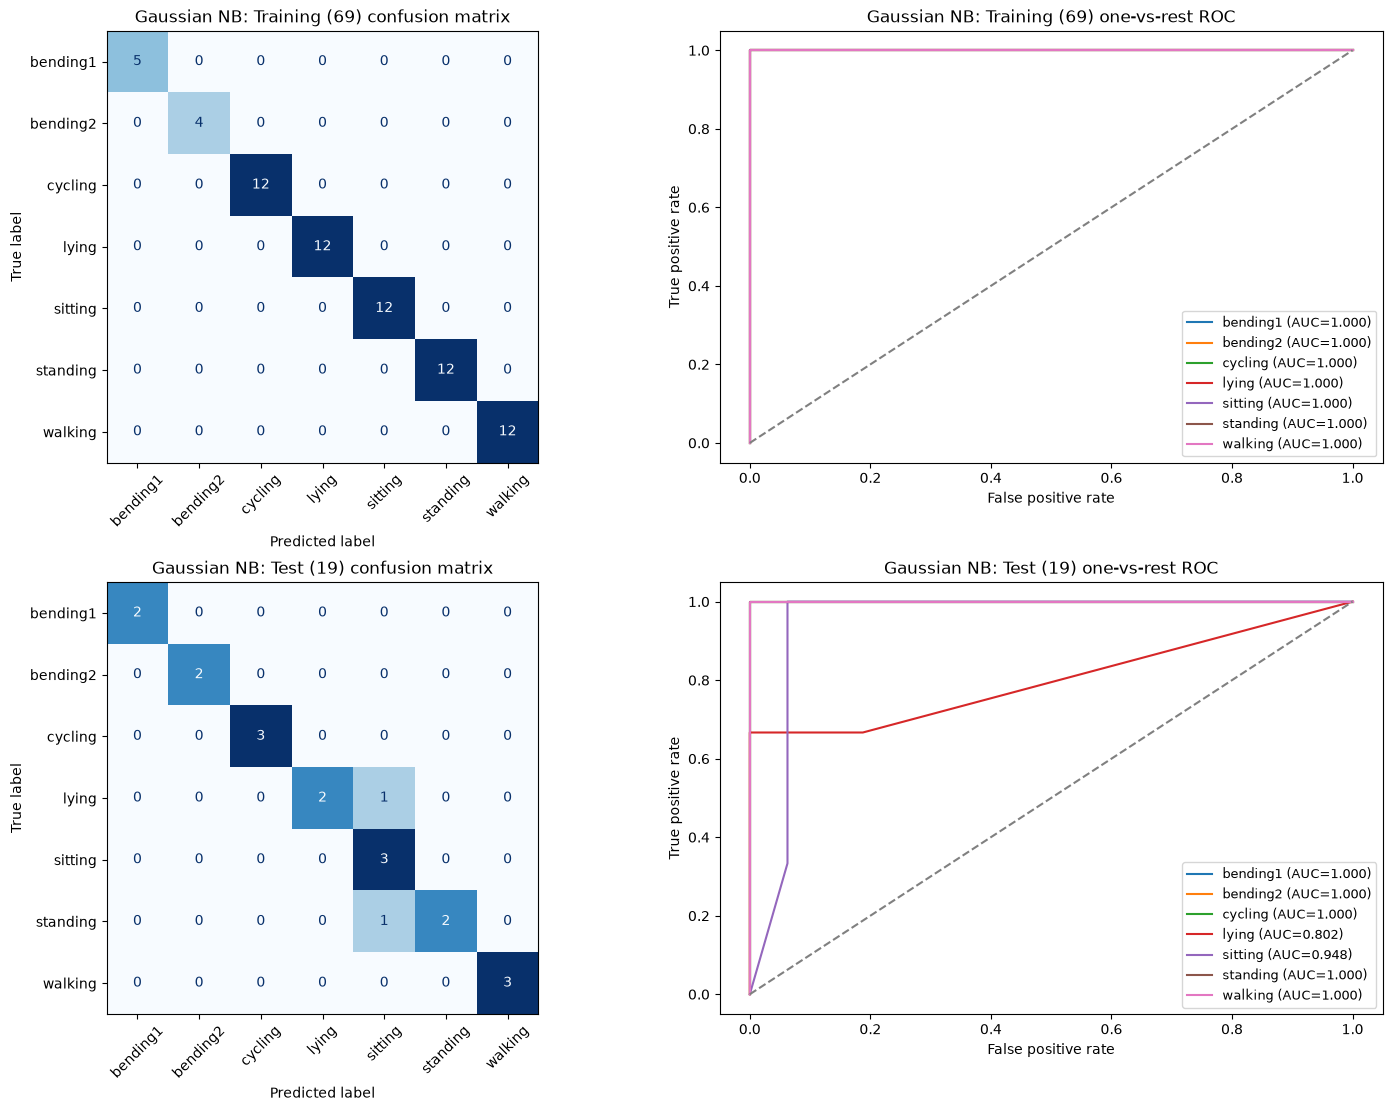

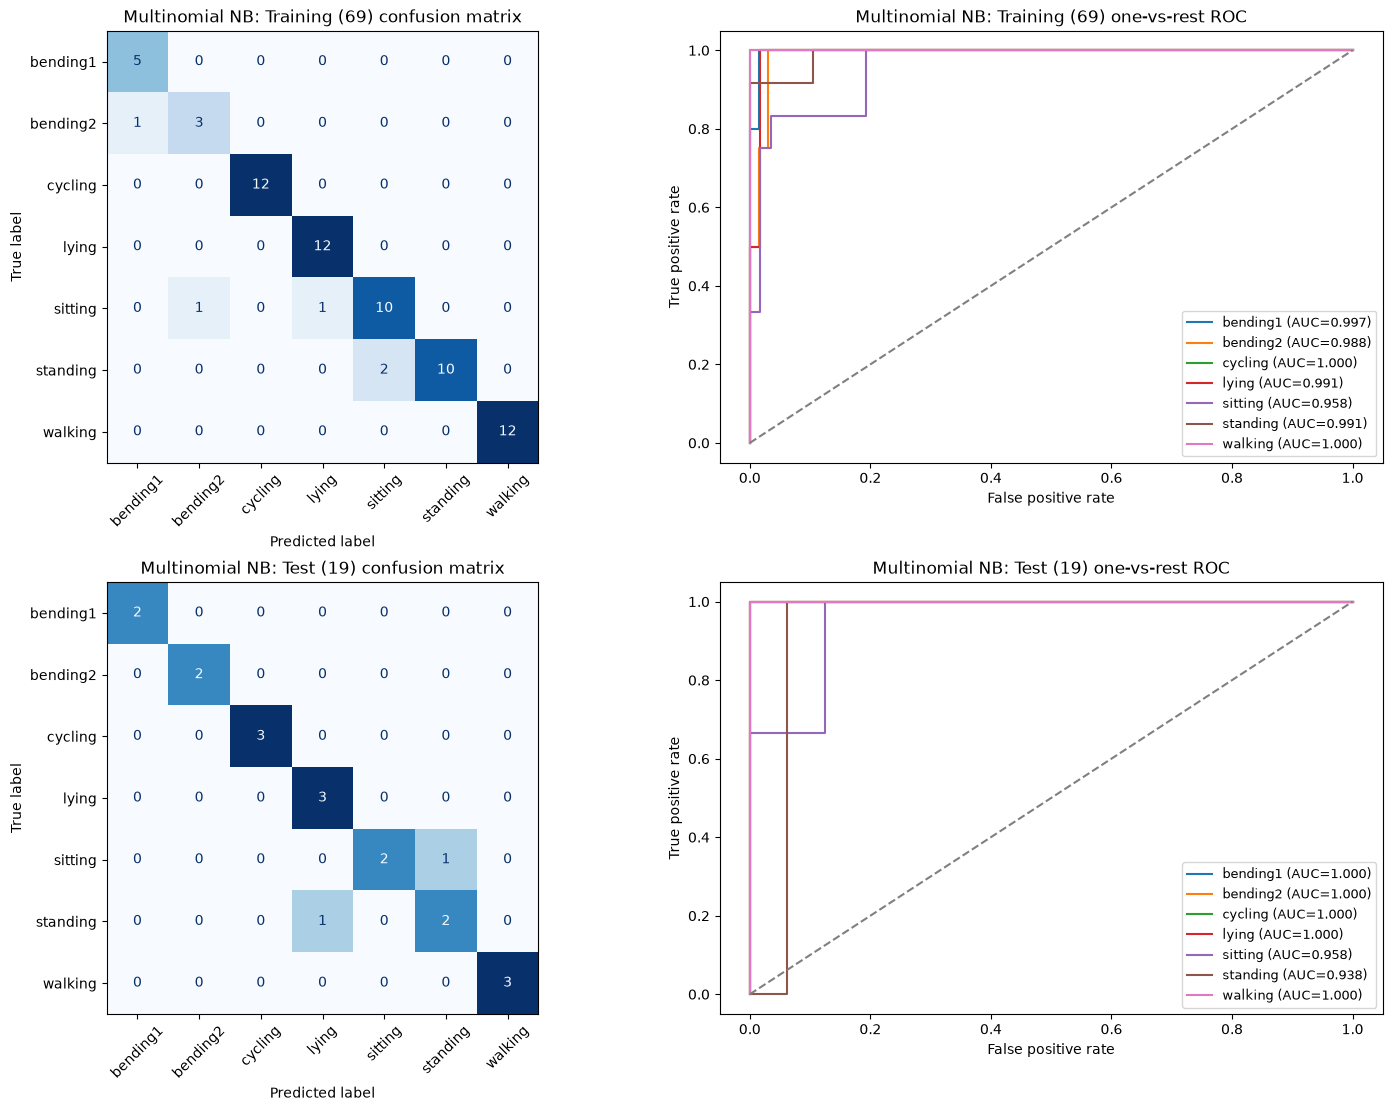

In [16]:
# Search segment counts separately for the two classifiers.
nb_estimators = {"Gaussian NB": GaussianNB(var_smoothing=1e-9),
                 "Multinomial NB": MultinomialNB(alpha=1.0)}
nb_search_rows = []
with threadpool_limits(limits=1):
    for name, estimator in nb_estimators.items():
        for segments in range(1, 21):
            X_nb = segment_features[segments]
            assert (X_nb.to_numpy() >= 0).all()
            scores = cross_val_score(estimator, X_nb, y_train_multi, cv=multi_folds,
                                     scoring="accuracy", n_jobs=1, error_score="raise")
            nb_search_rows.append({"Model": name, "segments": segments,
                                   "mean_cv_accuracy": scores.mean()})
nb_cv_results = pd.DataFrame(nb_search_rows)
display(nb_cv_results.pivot(index="segments", columns="Model", values="mean_cv_accuracy"))

# Select the smallest segment count among tied best scores, then refit.
nb_best_rows = []
nb_tie_tables = []
nb_models = {}
nb_test_features = {}
nb_predictions = {}
nb_probabilities = {}
nb_metric_rows = []
for name, estimator in nb_estimators.items():
    results = nb_cv_results.loc[nb_cv_results["Model"] == name]
    best_score = results["mean_cv_accuracy"].max()
    ties = results.loc[np.isclose(results["mean_cv_accuracy"], best_score, rtol=0, atol=1e-12)]
    ties = ties.sort_values("segments")
    nb_tie_tables.append(ties)
    segments = int(ties.iloc[0]["segments"])
    nb_best_rows.append({"Model": name, "segments": segments, "mean_cv_accuracy": best_score})
    X_train_nb = segment_features[segments]
    X_test_nb = extract_segment_features(test_recordings, segments, test_features.index)
    assert X_test_nb.columns.equals(X_train_nb.columns)
    assert (X_test_nb.to_numpy() >= 0).all()
    with threadpool_limits(limits=1):
        estimator.fit(X_train_nb, y_train_multi)
    nb_models[name] = estimator
    nb_test_features[name] = X_test_nb
    for dataset, X, truth in [("Training (69)", X_train_nb, y_train_multi),
                               ("Test (19)", X_test_nb, y_test_multi)]:
        predicted = estimator.predict(X)
        probabilities = estimator.predict_proba(X)
        nb_predictions[name, dataset] = predicted
        nb_probabilities[name, dataset] = probabilities
        nb_metric_rows.append({
            "Model": name, "Dataset": dataset,
            "Accuracy": accuracy_score(truth, predicted),
            "Error": np.mean(predicted != truth.to_numpy()),
            "Macro OvR AUC": roc_auc_score(truth, probabilities, labels=multi_classes,
                                           multi_class="ovr", average="macro")
        })
nb_best_settings = pd.DataFrame(nb_best_rows)
nb_tied_best = pd.concat(nb_tie_tables, ignore_index=True)
nb_metrics = pd.DataFrame(nb_metric_rows)
display(nb_best_settings)
display(nb_tied_best)
display(nb_metrics)

# Show each classifier's training and test confusion matrices and ROC curves.
nb_figures = []
for name in nb_estimators:
    fig_nb, axes_nb = plt.subplots(2, 2, figsize=(14, 11), layout="constrained")
    nb_figures.append(fig_nb)
    for row, dataset, truth in [(0, "Training (69)", y_train_multi),
                                 (1, "Test (19)", y_test_multi)]:
        predicted = nb_predictions[name, dataset]
        probabilities = nb_probabilities[name, dataset]
        ConfusionMatrixDisplay.from_predictions(truth, predicted, labels=multi_classes,
            ax=axes_nb[row, 0], cmap="Blues", colorbar=False, xticks_rotation=45)
        axes_nb[row, 0].set_title(f"{name}: {dataset} confusion matrix")
        for column, activity in enumerate(multi_classes):
            binary_truth = (truth == activity).astype(int)
            fpr, tpr, _ = roc_curve(binary_truth, probabilities[:, column])
            area = roc_auc_score(binary_truth, probabilities[:, column])
            axes_nb[row, 1].plot(fpr, tpr, label=f"{activity} (AUC={area:.3f})")
        axes_nb[row, 1].plot([0, 1], [0, 1], "--", color="gray")
        axes_nb[row, 1].set(xlabel="False positive rate", ylabel="True positive rate",
                              title=f"{name}: {dataset} one-vs-rest ROC")
        axes_nb[row, 1].legend(loc="lower right", fontsize=9)
    plt.show()


Gaussian NB models features using normal distributions. Multinomial NB uses the nonnegative features directly, although continuous sensor measurements only approximate the count data it typically models.
I selected the segment count using five-fold cross-validation on training data. Both models chose one segment and achieve 89.47% test accuracy (two errors). Multinomial NB has higher CV accuracy and test macro AUC.


#### iii. Comparison


All three methods tie at 89.47% test accuracy (17/19), or 10.53% test error. L1 multinomial logistic regression is my preferred model because it has the highest CV accuracy (92.86%), versus 87.14% for Multinomial NB and 85.71% for Gaussian NB. Its test macro AUC is also highest (0.9940, versus 0.9851 and 0.9643 respectively). These results favor logistic regression for the tested setup, but the small test set does not establish a general winner.


## 3. ISLR 4.8.3

Let $\pi_k=P(Y=k)$. By Bayes' theorem, we assign $x$ to the class with the largest $\pi_k f_k(x)$, since the posterior denominator is the same for every class. Taking logs and dropping the common constant $-\frac12\log(2\pi)$ gives

$$
\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the square,

$$
\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x+
\log\pi_k-\log\sigma_k-\frac{\mu_k^2}{2\sigma_k^2}.
$$

The boundary between classes $k$ and $j$ satisfies $\delta_k(x)-\delta_j(x)=0$. Its coefficient of $x^2$ is

$$
\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.
$$

When the class variances differ, this term does not cancel, so the boundary equation is **quadratic**, rather than linear. Equal variances are the special case where the squared terms cancel and the rule reduces to LDA.


## 4. ISLR 4.8.7

Let $D$ mean that the company issues a dividend. We have $P(D)=0.8$, $P(D^c)=0.2$, $\mu_D=10$, $\mu_{D^c}=0$, and a common variance of $36$.

By Bayes' theorem,

$$
P(D\mid X=4)=\frac{0.8f_D(4)}{0.8f_D(4)+0.2f_{D^c}(4)}.
$$

The normal densities have the same leading factor $1/\sqrt{2\pi\cdot36}$, which cancels. Substituting the squared distances from the two means gives

$$
P(D\mid X=4)=
\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}
=\frac{0.8e^{-1/2}}{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.75185.
$$

The predicted probability of issuing a dividend is approximately **75.19%**.


## References

- [UCI AReM dataset](https://archive.ics.uci.edu/dataset/366/activity+recognition+system+based+on+multisensor+data+fusion+arem): supplied as `../data/AReM.zip`.
- [tsfresh feature descriptions](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html): time-domain features
- pandas: [standard deviation](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html), [quantiles](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html), [sampling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html), and [correlation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
- NumPy: [percentiles](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html) and [array splitting](https://numpy.org/doc/stable/reference/generated/numpy.array_split.html).
- Matplotlib: [scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html), [subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), and [boxplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html).
- Statsmodels: [ANOVA effect sizes](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway._fstat2effectsize.html), [Logit](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html), and [estimation pitfalls](https://www.statsmodels.org/stable/pitfalls.html).
- scikit-learn: [RFE](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html), [RFECV](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFECV.html), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), and [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html).
- scikit-learn: [ROC curves](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html), [multiclass ROC](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html), [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html), and [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html).
- Fithian and Hastie (2014), [Local case-control sampling](https://arxiv.org/pdf/1306.3706): discussion of standard case-control sampling and intercept correction.
- *An Introduction to Statistical Learning, with Applications in R*, second edition

Generative AI assistance: I used Codex to help with planning, debugging and explanations wherever I got stuck. Some of the prompts I used are as follows: 

- Is breaking the training set time series into 2 supposed to help with the separation? I'm not able to observe a significant difference.
- How do I go about implementing this binary classification task using logistic regression?
- How do I use backward selection using sklearn.feature selection or glm in R? Will it lead to better results than what I currently have?
- How do I implement 5-fold cross validation in python?
- What is recursive feature elimination? Why is it necessary? Explain in detail with an example
- How to I implement RFE to this particular problem?
- How do I go about implementing the cross validation?
- I see a suggestion that limiting the max iterations is a way to deal with the regression's instability. How do I know how much to limit it to? Is this something I just need to experiment to find out?
- The assignment suggests implementing stratified cross validation? How is it different from the version I implemented? Why is it needed? Explain with the help of an example.
- How do I view the imbalance classes?
- How do I build the confusion matrices in python?
- What is L1 penalized regression? How is it different from what I implemented in the previous sections?
- I see that we are allowed to tune C instead of the lambda variable? What would that change? Would it lead to a better result?
- How do I build an L1-penalized multinomial regression model for the same task? Explain with a clear and concise example.
- Explain how confusion matrices and ROC curves are defined for multiclass classification. Give me a simple example to illuustrate this point.
- How do I implement these metrics? The assignment lists pROC but I am not sure how or why to use that.
- How do I use a Naive Bayes classifier? Illustrate with an example. Highlight the sections where Gaussian and mutlinomial priors are used.
- I need to write math formulas and terms for some free response questions. Help me format the responses to be clear and accurate in markdown format

